# Exploration

In [27]:
%load_ext autoreload
%autoreload 2

import importlib
from ccf_ml import file_utils
from ccf_ml.visualization.bivariate import categorical_categorical
from ccf_ml.visualization.bivariate import categorical_numeric
from ccf_ml.visualization.bivariate import condition_categorical
importlib.reload(file_utils)
importlib.reload(categorical_categorical)
importlib.reload(categorical_numeric)
importlib.reload(condition_categorical)

from ccf_ml.file_utils import (
    get_train_csv_path,
    get_script_plot_dir,
    get_script_table_dir,
)
import matplotlib.pyplot as plt
import pandas as pd 

DELIMITER_COUNT = 50 
DELIMITER_VALUE = "-" * DELIMITER_COUNT
NOTEBOOK_STEM = "eda_1_notebook"
tables_dir = get_script_table_dir(NOTEBOOK_STEM)

TARGET = "is_fraud"
TARGET_GIVEN_LABELS = {0: "not fraud", 1: "fraud"}

# variable for the column names

AUTH_METHOD_COL = "auth_method"
MERCHANT_CATEGORY_COL = "merchant_category"
CARD_TYPE_COL = "card_type"
CHANNEL_COL = "channel"
DEVICE_TYPE_COL = "device_type"

IS_FOREIGN_TRANSACTION_COL = "is_foreign_transaction"
IS_NEW_MERCHANT_COL = "is_new_merchant"
USED_VPN_COL = "used_vpn"
IP_COUNTRY_MISMATCH_COL = "ip_country_mismatch"
BILLING_SHIPPING_MISMATCH_COL = "billing_shipping_mismatch"
IS_AI_GENERATED_SCAM_ATTEMPT_COL = "is_ai_generated_scam_attempt"


train_df = pd.read_csv(get_train_csv_path())
# remove the id since it is useless
train_df = train_df.drop(columns=['id'])
print(train_df.head())


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
   amount_usd  hours_since_last_txn  txn_count_last_24h  \
0       61.16                  9.77                   1   
1       24.83                  1.54                   3   
2        6.36                  1.20                   4   
3       37.44                  5.13                   4   
4      653.85                  0.80                   4   

   distance_from_home_km  card_age_months  customer_age  account_balance_usd  \
0                  17.78               48            56              1269.35   
1                  13.06               38            28              3233.00   
2                   8.17               50            55              1046.88   
3                   8.67               48            48              2217.67   
4                  11.69               37            52              3291.06   

   cvv_retry_count  velocity_score  time_of_day_hour  ...  auth_method  \
0 

In [28]:
# the next step is trying to understand the columns: mainly whether they are numerical or categorical
# usually if the column is not numerical, then it is categorical. 
# if a column is numerical then it depends on the number of unique values. 
# a categorical column with a lot of unique values are the most problematica ones. 
col_types = train_df.dtypes
print(col_types)

amount_usd                      float64
hours_since_last_txn            float64
txn_count_last_24h                int64
distance_from_home_km           float64
card_age_months                   int64
customer_age                      int64
account_balance_usd             float64
cvv_retry_count                   int64
velocity_score                  float64
time_of_day_hour                  int64
day_of_week                       int64
merchant_risk_score             float64
prior_disputes                    int64
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool
is_fraud                        float64


```
merchant_category                   str
card_type                           str
auth_method                         str
channel                             str
device_type                         str
is_foreign_transaction             bool
is_new_merchant                    bool
used_vpn                           bool
ip_country_mismatch                bool
billing_shipping_mismatch          bool
is_ai_generated_scam_attempt       bool
```

These columns are definitely categorical. we do not have any information about the cards overall or the time of the transactions 
it would be interesting to try to reconstruct the profile of the cards and the transactions.

In [29]:
unique_vals_per_col = train_df.nunique()
print(unique_vals_per_col)

amount_usd                      13387
hours_since_last_txn             3633
txn_count_last_24h                 12
distance_from_home_km            4365
card_age_months                    49
customer_age                       64
account_balance_usd             43317
cvv_retry_count                     4
velocity_score                    666
time_of_day_hour                   24
day_of_week                         7
merchant_risk_score               950
prior_disputes                      5
merchant_category                  12
card_type                           5
auth_method                         5
channel                             5
device_type                         8
is_foreign_transaction              2
is_new_merchant                     2
used_vpn                            2
ip_country_mismatch                 2
billing_shipping_mismatch           2
is_ai_generated_scam_attempt        2
is_fraud                            2
dtype: int64


```
amount_usd: numerical

hours_since_last_tnx: probably numerical if we are not using integer hours

time_of_day_hour, day_of_week: clearly categorical.

velocity_score: numerical

customer_age: numerical but not continous (closer to categorical)

card_age_months: probably has a predefined set of possible values 
```

In [30]:
y_distribution = train_df[TARGET].value_counts(normalize=True)
print(y_distribution) # so 1.67% of the transactions are fraudulent

bool_cols = train_df.select_dtypes(include=['bool']).columns

for bc in bool_cols:
    print(f"{bc}: {train_df[bc].value_counts(normalize=True)}")

is_fraud
0.0    0.9833
1.0    0.0167
Name: proportion, dtype: float64
is_foreign_transaction: is_foreign_transaction
False    0.982716
True     0.017284
Name: proportion, dtype: float64
is_new_merchant: is_new_merchant
False    0.847534
True     0.152466
Name: proportion, dtype: float64
used_vpn: used_vpn
False    0.966191
True     0.033809
Name: proportion, dtype: float64
ip_country_mismatch: ip_country_mismatch
False    0.983839
True     0.016161
Name: proportion, dtype: float64
billing_shipping_mismatch: billing_shipping_mismatch
False    0.987065
True     0.012935
Name: proportion, dtype: float64
is_ai_generated_scam_attempt: is_ai_generated_scam_attempt
False    0.996716
True     0.003284
Name: proportion, dtype: float64


In [31]:
# quick analysis of the other categorical columns
categorical_cols = train_df.select_dtypes(include=['object', 'str', 'bool']).columns

for cc in categorical_cols:
    print(f"{cc}: {train_df[cc].value_counts(normalize=True)}")
    print("-" * DELIMITER_COUNT)

merchant_category: merchant_category
Online Retail      0.221580
Groceries          0.203694
Restaurants        0.144808
Fuel               0.085548
Electronics        0.069565
Streaming          0.067427
Utilities          0.060042
Healthcare         0.051273
Travel             0.041024
Gaming             0.033979
Gift Cards         0.013509
Crypto Exchange    0.007550
Name: proportion, dtype: float64
--------------------------------------------------
card_type: card_type
Visa          0.492887
Mastercard    0.364102
Amex          0.065428
RuPay         0.052960
Discover      0.024623
Name: proportion, dtype: float64
--------------------------------------------------
auth_method: auth_method
3D Secure            0.300069
OTP                  0.250269
PIN                  0.220041
Biometric            0.133816
No Authentication    0.095805
Name: proportion, dtype: float64
--------------------------------------------------
channel: channel
Online         0.391364
POS            0.294967

# Target Interaction with the predictors

## Fraud and Authentication Method 

The distribution of authentication methods

```
auth_method:      auth_method
3D Secure            0.300069
OTP                  0.250269
PIN                  0.220041
Biometric            0.133816
No Authentication    0.095805
``` 

The natural quantities to estimate are: 

$$
P(\text{auth\_method} = \text{auth\_method}_i ~ | ~ \text{fraud} = True)
$$

and 

$$
P(\text{fraud} = True ~ | ~ \text{auth\_method} = \text{auth\_method}_i)
$$ 

auth_method  No Authentication  Biometric     PIN     OTP  3D Secure
is_fraud                                                            
0.0                     0.0912     0.1354  0.2218  0.2509     0.3007
1.0                     0.3697     0.0400  0.1144  0.2108     0.2650
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\fraud_and_authentication_method\auth_method_given_fraud.png


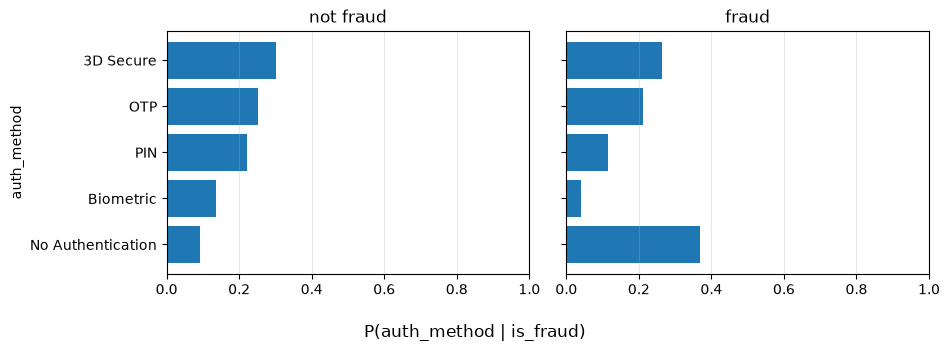

In [32]:
counts = pd.crosstab(train_df[TARGET], train_df[AUTH_METHOD_COL])
share = counts.div(counts.sum(axis=1), axis=0)
order = (
    train_df[AUTH_METHOD_COL]
    .value_counts()
    .sort_values(ascending=True)
    .index
)
share = share.loc[:, order]

fig, axes = categorical_categorical.plot_conditional_share(
    share,
    feature=AUTH_METHOD_COL,
    given=TARGET,
    given_labels=TARGET_GIVEN_LABELS,
)
share_path = tables_dir / "auth_method_given_fraud.csv"
share.to_csv(share_path)
plot_path = (
    get_script_plot_dir(
        NOTEBOOK_STEM, section="fraud_and_authentication_method"
    )
    / "auth_method_given_fraud.png"
)
fig.savefig(plot_path, dpi=140)
print(share.round(4))
print(f"saved {plot_path}")
plt.show()

In [33]:
# the other way around now. Given the authentication method, can we estimate the probability of fraud ? 
d_absolute = train_df[[AUTH_METHOD_COL, TARGET]].pivot_table(index=AUTH_METHOD_COL, values=TARGET, columns=TARGET,aggfunc="count")

# COMPUTE THE PERCENTAGE OF FRADULENT TRANSACTIONS PER AUTHENTICATION METHOD
d_relative = train_df[[AUTH_METHOD_COL, TARGET]].pivot_table(index=AUTH_METHOD_COL, values=TARGET, aggfunc="mean")
# d_relative = (d_relative * 100).round(2).map(lambda p: f"{p:.2f}%") 

# the more interesting thing here is to compute the the ratio between P(fraud) and P(fraud | auth_method)
# this is the lift of the authentication method

base_rate = train_df[[TARGET]].mean(axis=0) 

# we need to divide the d_relative by the base_rate
d_lift = d_relative.div(base_rate, axis=1)

d_relative['lift_to_base_rate'] = d_lift.squeeze().round(2) 

# now convert the d_relative to a percentage

d_relative[TARGET] =  (d_relative[TARGET] * 100).round(2).map(lambda p: f"{p:.2f}%") 

print(d_absolute)

print(DELIMITER_VALUE)
print(DELIMITER_VALUE)

print(d_relative.sort_values(by="lift_to_base_rate", ascending=False))

is_fraud              0.0   1.0
auth_method                    
3D Secure          206938  3098
Biometric           93198   468
No Authentication   62738  4322
OTP                172714  2464
PIN                152683  1337
--------------------------------------------------
--------------------------------------------------
                  is_fraud  lift_to_base_rate
auth_method                                  
No Authentication    6.44%               3.86
3D Secure            1.47%               0.88
OTP                  1.41%               0.84
PIN                  0.87%               0.52
Biometric            0.50%               0.30


So what does this tell us ? The authentication method on its own is not enough to predict fraud. However, it is very likely to believe that 

The random variable E[Y | auth_method] has a different distribution for each value of E[Y | auth_method]. 

TO be more concrete, it requires the same set of predictors to be more extreme to flag a transaction if the authentication method is Biometric than if there were no authentication at all. Weirdly Enough, PIN is more secure than `3D Secure` and `OTP`. 

The `3d Secure` and `OTP` options are hence considered slightly less interesting for further exploration. a base rate of $\approx 1$ suggests that this piece of information has much less impact on the target than other specific values; additionally, we might group them together unless there is some fundamental difference with other meaningful predictors. 

## Fraud and Merchant Category

The interaction between the merchant and fradulent transactions is also interesting 

```
merchant_category: merchant_category
Online Retail      0.221
Groceries          0.203
Restaurants        0.144
Fuel               0.085
Electronics        0.069
Streaming          0.067
Utilities          0.060
Healthcare         0.051
Travel             0.041
Gaming             0.033
Gift Cards         0.013
Crypto Exchange    0.007
```

merchant_category  Crypto Exchange  Gift Cards  Gaming  Travel  Healthcare  \
is_fraud                                                                     
0.0                         0.0072      0.0127  0.0327  0.0409      0.0515   
1.0                         0.0295      0.0590  0.1122  0.0457      0.0395   

merchant_category  Utilities  Streaming  Electronics    Fuel  Restaurants  \
is_fraud                                                                    
0.0                   0.0602     0.0670       0.0686  0.0859       0.1456   
1.0                   0.0497     0.0908       0.1284  0.0634       0.0992   

merchant_category  Groceries  Online Retail  
is_fraud                                     
0.0                   0.2049         0.2228  
1.0                   0.1356         0.1471  
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\fraud_and_merchant_strategy\merchant_category_given_fraud.png


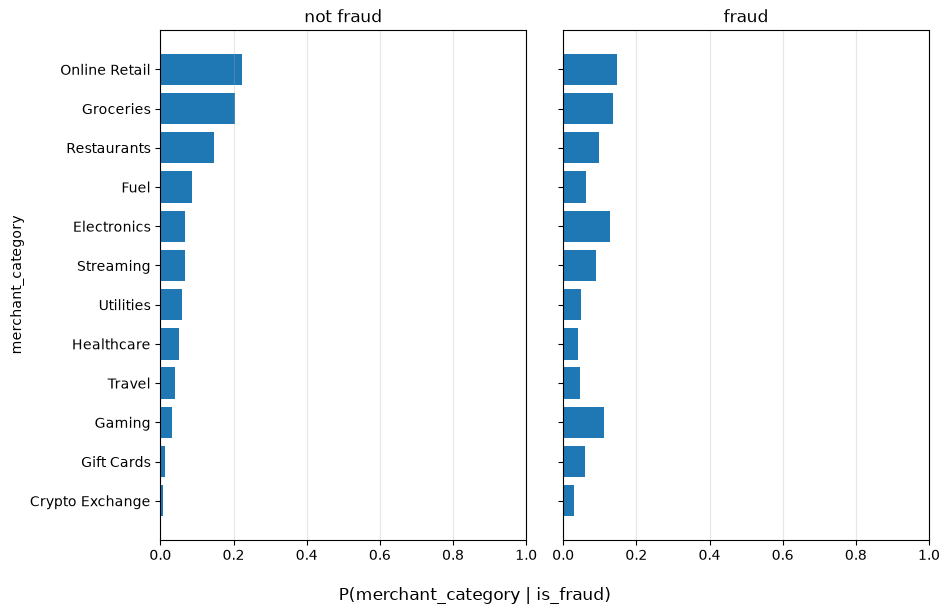

In [34]:
# P(merchant_category | is_fraud)

counts = pd.crosstab(train_df[TARGET], train_df[MERCHANT_CATEGORY_COL])
share = counts.div(counts.sum(axis=1), axis=0)
order = (
    train_df[MERCHANT_CATEGORY_COL]
    .value_counts()
    .sort_values(ascending=True)
    .index
)
share = share.loc[:, order]

fig, axes = categorical_categorical.plot_conditional_share(
    share,
    feature=MERCHANT_CATEGORY_COL,
    given=TARGET,
    given_labels=TARGET_GIVEN_LABELS,
)
share_path = tables_dir / "merchant_category_given_fraud.csv"
share.to_csv(share_path)
plot_path = (
    get_script_plot_dir(
        NOTEBOOK_STEM, section="fraud_and_merchant_strategy"
    )
    / "merchant_category_given_fraud.png"
)
fig.savefig(plot_path, dpi=140)
print(share.round(4))
print(f"saved {plot_path}")
plt.show()


In [35]:
# the other way around now. Given the authentication method, can we estimate the probability of fraud ? 
d_absolute = train_df[[MERCHANT_CATEGORY_COL , TARGET]].pivot_table(index=MERCHANT_CATEGORY_COL, values=TARGET, columns=TARGET,aggfunc="count")

# COMPUTE THE PERCENTAGE OF FRADULENT TRANSACTIONS PER AUTHENTICATION METHOD
d_relative = train_df[[MERCHANT_CATEGORY_COL, TARGET]].pivot_table(index=MERCHANT_CATEGORY_COL, values=TARGET, aggfunc="mean")
# d_relative = (d_relative * 100).round(2).map(lambda p: f"{p:.2f}%") 

# the more interesting thing here is to compute the the ratio between P(fraud) and P(fraud | auth_method)
# this is the lift of the authentication method

base_rate = train_df[[TARGET]].mean(axis=0) 

# we need to divide the d_relative by the base_rate
d_lift = d_relative.div(base_rate, axis=1)

d_relative['lift_to_base_rate'] = d_lift.squeeze().round(2) 

# now convert the d_relative to a percentage

d_relative[TARGET] =  (d_relative[TARGET] * 100).round(2).map(lambda p: f"{p:.2f}%") 

print(d_absolute)

print(DELIMITER_VALUE)
print(DELIMITER_VALUE)

print(d_relative.sort_values(by="lift_to_base_rate", ascending=False))

is_fraud              0.0   1.0
merchant_category              
Crypto Exchange      4940   345
Electronics         47192  1501
Fuel                59139   741
Gaming              22473  1311
Gift Cards           8766   690
Groceries          140993  1585
Healthcare          35427   462
Online Retail      153378  1719
Restaurants        100201  1159
Streaming           46135  1061
Travel              28181   534
Utilities           41446   581
--------------------------------------------------
--------------------------------------------------
                  is_fraud  lift_to_base_rate
merchant_category                            
Gift Cards           7.30%               4.37
Crypto Exchange      6.53%               3.91
Gaming               5.51%               3.30
Electronics          3.08%               1.85
Streaming            2.25%               1.35
Travel               1.86%               1.11
Utilities            1.38%               0.83
Healthcare           1.29%          

What does this tell us ? 

The merchant category is meaningful (or at least some specific values). 

## Each predictor vs fraud


Authentication method and merchant category are above. The rest of this section uses the same two views for every remaining predictor, so the strong univariate signals are visible before any leftover-subset analysis.

Categorical (including flags and low-cardinality integers): $P(X \mid \text{is\_fraud})$ as a mix, then $P(\text{is\_fraud} \mid X)$ with lift to the base rate.

Numeric: $P(X \le t \mid \text{is\_fraud})$ as a CDF.


In [36]:
# continue 

# import numpy as np

# EACH_PREDICTOR_SECTION = "each_predictor_vs_fraud"
# LOW_CARDINALITY_INT_MAX = 24
# ALREADY_DETAILED_CATS = {AUTH_METHOD_COL, MERCHANT_CATEGORY_COL}


# def is_categorical_predictor(frame, col):
#     series = frame[col]
#     if pd.api.types.is_bool_dtype(series):
#         return True
#     if pd.api.types.is_object_dtype(series) or pd.api.types.is_string_dtype(
#         series
#     ):
#         return True
#     if (
#         pd.api.types.is_integer_dtype(series)
#         and series.nunique() <= LOW_CARDINALITY_INT_MAX
#     ):
#         return True
#     return False


# predictor_cols = [col for col in train_df.columns if col != TARGET]
# categorical_predictors = [
#     col for col in predictor_cols if is_categorical_predictor(train_df, col)
# ]
# numeric_predictors = [
#     col for col in predictor_cols if col not in categorical_predictors
# ]
# remaining_categorical_predictors = [
#     col for col in categorical_predictors if col not in ALREADY_DETAILED_CATS
# ]
# print("categorical predictors", categorical_predictors)
# print("remaining categoricals", remaining_categorical_predictors)
# print("numeric predictors", numeric_predictors)

# base_rate = train_df[[TARGET]].mean(axis=0)
# print(f"base_rate={float(base_rate.iloc[0]):.4f}")

# cat_rank_rows = []
# for col in categorical_predictors:
#     grouped = train_df.groupby(col, observed=True)[TARGET]
#     rate = grouped.mean()
#     n = grouped.size()
#     n_fraud = grouped.sum()
#     lift = rate / float(base_rate.iloc[0])
#     cat_rank_rows.append(
#         {
#             "feature": col,
#             "n_levels": int(rate.size),
#             "min_rate": float(rate.min()),
#             "max_rate": float(rate.max()),
#             "min_lift": float(lift.min()),
#             "max_lift": float(lift.max()),
#             "lift_span": float(lift.max() / lift.min()) if lift.min() > 0 else np.inf,
#             "level_at_max_lift": rate.idxmax(),
#             "n_at_max_lift": int(n.loc[rate.idxmax()]),
#             "n_fraud_at_max_lift": float(n_fraud.loc[rate.idxmax()]),
#         }
#     )
# cat_rank = pd.DataFrame(cat_rank_rows).sort_values(
#     "max_lift", ascending=False
# )
# print(DELIMITER_VALUE)
# print("P(fraud | level) ranking")
# print(cat_rank.round(4).to_string(index=False))
# cat_rank_path = tables_dir / "each_predictor_categorical_lift_ranking.csv"
# cat_rank.to_csv(cat_rank_path, index=False)
# print(f"saved {cat_rank_path}")

# num_rank_rows = []
# for col in numeric_predictors:
#     key = pd.qcut(train_df[col], 10, duplicates="drop")
#     decile_rate = train_df.groupby(key, observed=True)[TARGET].mean()
#     lift = decile_rate / float(base_rate.iloc[0])
#     q = train_df.groupby(TARGET)[col].quantile([0.5, 0.9, 0.99]).unstack()
#     num_rank_rows.append(
#         {
#             "feature": col,
#             "bottom_decile_rate": float(decile_rate.iloc[0]),
#             "top_decile_rate": float(decile_rate.iloc[-1]),
#             "bottom_decile_lift": float(lift.iloc[0]),
#             "top_decile_lift": float(lift.iloc[-1]),
#             "p50_not_fraud": float(q.loc[0.0, 0.5]),
#             "p50_fraud": float(q.loc[1.0, 0.5]),
#             "p90_not_fraud": float(q.loc[0.0, 0.9]),
#             "p90_fraud": float(q.loc[1.0, 0.9]),
#         }
#     )
# num_rank = pd.DataFrame(num_rank_rows).sort_values(
#     "top_decile_lift", ascending=False
# )
# print(DELIMITER_VALUE)
# print("numeric top vs bottom decile ranking")
# print(num_rank.round(4).to_string(index=False))
# num_rank_path = tables_dir / "each_predictor_numeric_decile_ranking.csv"
# num_rank.to_csv(num_rank_path, index=False)
# print(f"saved {num_rank_path}")


$P(X \mid \text{is\_fraud})$ and $P(\text{is\_fraud} \mid X)$ for every remaining categorical predictor, including the binary flags and the low-cardinality integers.


In [37]:
# for col in remaining_categorical_predictors:
#     print(DELIMITER_VALUE)
#     print(col)
#     counts = pd.crosstab(train_df[TARGET], train_df[col])
#     share = counts.div(counts.sum(axis=1), axis=0)
#     if pd.api.types.is_bool_dtype(train_df[col]) or pd.api.types.is_integer_dtype(
#         train_df[col]
#     ):
#         order = sorted(share.columns)
#     else:
#         order = (
#             train_df[col]
#             .value_counts()
#             .sort_values(ascending=True)
#             .index
#         )
#     share = share.reindex(columns=order)
#     fig, axes = categorical_categorical.plot_conditional_share(
#         share,
#         feature=col,
#         given=TARGET,
#         given_labels=TARGET_GIVEN_LABELS,
#     )
#     share_path = tables_dir / f"{col}_given_fraud.csv"
#     share.to_csv(share_path)
#     plot_path = (
#         get_script_plot_dir(NOTEBOOK_STEM, section=EACH_PREDICTOR_SECTION)
#         / f"{col}_given_fraud.png"
#     )
#     fig.savefig(plot_path, dpi=140)
#     print(share.round(4))
#     print(f"saved {plot_path}")
#     plt.show()

#     d_absolute = train_df[[col, TARGET]].pivot_table(
#         index=col, values=TARGET, columns=TARGET, aggfunc="count"
#     )
#     d_relative = train_df[[col, TARGET]].pivot_table(
#         index=col, values=TARGET, aggfunc="mean"
#     )
#     d_lift = d_relative.div(base_rate, axis=1)
#     d_relative = d_relative.copy()
#     d_relative["lift_to_base_rate"] = d_lift.squeeze().round(2)
#     d_relative[TARGET] = (
#         (d_relative[TARGET] * 100).round(2).map(lambda p: f"{p:.2f}%")
#     )
#     print(d_absolute)
#     print(DELIMITER_VALUE)
#     print(d_relative.sort_values(by="lift_to_base_rate", ascending=False))


$P(X \le t \mid \text{is\_fraud})$ for every numeric predictor. Money columns use a log $x$-axis when every value is positive.


In [38]:
# for col in numeric_predictors:
#     print(DELIMITER_VALUE)
#     print(col)
#     print(
#         train_df.groupby(TARGET)[col]
#         .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
#         .round(3)
#     )
#     cdf_parts = []
#     for level, part in train_df.groupby(TARGET, sort=True):
#         x = np.sort(part[col].to_numpy())
#         cdf = np.arange(1, len(x) + 1) / len(x)
#         cdf_parts.append(pd.DataFrame({col: x, "cdf": cdf, TARGET: level}))
#     curves = pd.concat(cdf_parts, ignore_index=True)
#     x_scale = "log" if col.endswith("_usd") and bool((curves[col] > 0).all()) else "linear"
#     fig, ax = categorical_numeric.plot_conditional_cdf(
#         curves,
#         x=col,
#         cdf="cdf",
#         group=TARGET,
#         x_scale=x_scale,
#         group_labels=TARGET_GIVEN_LABELS,
#     )
#     plot_path = (
#         get_script_plot_dir(NOTEBOOK_STEM, section=EACH_PREDICTOR_SECTION)
#         / f"{col}_cdf_given_fraud.png"
#     )
#     fig.savefig(plot_path, dpi=140)
#     print(f"saved {plot_path} x_scale={x_scale}")
#     plt.show()


# Conclusions on Predictors


Base: $n=699960$, $n_{\text{fraud}}=11689$, $P(y=1)=1.67\%$.

The plots above show two different things. Lift and a CDF gap answer "does $X$ move $Y$?". A partition atom needs something else: a **region of $X$ with large occupancy and almost no remaining fraud**. A smooth expected trend is useful for a model. It is not, on its own, a slab you can set to $0$.

ROC AUC is rank-only. Setting a region $S$ to $0$ means those rows are tied at the bottom, strictly below everything not in $S$. The exact number $0$ vs $10^{-6}$ does not matter. The constraint is: $S$ must be large, and $n_{\text{fraud}}(S)$ must be a handful (the $10$--$15$ scale). The five alarm flags are **cut 1** of that process, not the end of it. The rest of the sample space has to be split with **other columns**, into **disjoint** regions.

---

**Hard high-fraud slabs.** Isolate these first. Their `True` / hot level is rare and concentrated. Their `False` / cold level is almost the whole dataset and still holds most of the fraud, so it is **not** a near-impossible region.

- `ip_country_mismatch`: `True` is $1.6\%$ of rows, $16.0\%$ of fraud, rate $16.5\%$ ($9.9\times$). `False` still has $9823$ frauds.
- `is_ai_generated_scam_attempt`: `True` is $0.33\%$ of rows, $3.0\%$ of fraud, rate $15.2\%$ ($9.1\times$). Tiny occupancy; almost no mass on `False` is removed.
- `billing_shipping_mismatch`: `True` is $1.3\%$ of rows, $10.1\%$ of fraud, rate $13.0\%$ ($7.8\times$).
- `is_foreign_transaction`: `True` is $1.7\%$ of rows, $13.0\%$ of fraud, rate $12.6\%$ ($7.5\times$).
- `used_vpn`: `True` is $3.4\%$ of rows, $13.3\%$ of fraud, rate $6.6\%$ ($3.9\times$). Largest of these flags by rows, weakest by rate.
- `cvv_retry_count`: the actual interaction is a **spike**, not a gentle count. Retry $0$ is $91.7\%$ of rows and **$51\%$ of fraud** (rate $0.93\%$). Retry $1$ is $8.0\%$ of rows and $42\%$ of fraud (rate $8.8\%$). Retry $2$ is $1905$ rows and $795$ frauds (rate $41.7\%$). Zeroing `cvv=0` is impossible. Retry $\ge 1$ is another high slab ($57872$ rows, $5699$ frauds).
- `auth_method`: `No Authentication` is $9.6\%$ of rows and **$37\%$ of fraud** (rate $6.44\%$, $3.86\times$). `3D Secure` and `OTP` sit near the base rate. `PIN` is $0.87\%$ ($1337$ frauds). `Biometric` is the coldest level at $0.50\%$ ($93666$ rows, still **$468$ frauds**). Biometric is an atom only after AND with something that actually kills those $468$.
- `merchant_category`: Gift Cards / Crypto / Gaming / Electronics are hot ($7.3\%$, $6.5\%$, $5.5\%$, $3.1\%$). Everyday retail is cold relative to the base ($\approx 1.11\%$) but that is **volume**: Online Retail + Groceries + Restaurants still hold $\approx 38\%$ of fraud. A cold merchant is not a near-impossible region.
- `is_new_merchant`: `True` is $15\%$ of rows and $43\%$ of fraud (rate $4.7\%$, $2.8\times$). `False` still has $6637$ frauds.

Union of the five location/VPN/scam flags (cut 1): $7.6\%$ of rows, $40.7\%$ of fraud, rate $9.0\%$. Complement: $92.4\%$ of rows, $59.3\%$ of fraud, rate $1.07\%$. That complement is where the other atoms have to work.

---

**Candidate cold atoms.** These are the columns that can actually define a near-impossible-fraud region, or that only become that after AND.

- `merchant_risk_score`: the name predicts a ranking feature, and the CDF gap is real (fraud sits to the right). That body trend is **not** the useful fact. On this train set there is a **hard floor**: no fraud below $13.1$ ($12736$ rows, $n_{\text{fraud}}=0$). The left tail stays rare after that: $\le 15$ is $23872$ rows and $12$ frauds. That is the occupancy / $n_{\text{fraud}}$ shape the post-processing strategy asked for. The body of the score is for the model.
- `velocity_score`: same split of roles. Fraud CDF is shifted right, as the name suggests. The usable atom is the **left pile**, not the slope: `velocity_score = 0` is $48499$ rows and $19$ frauds. Bottom $5\%$ is $10$ frauds; bottom $10\%$ is $81$. There is no train-set hard floor (min fraud velocity is $0$). Combining this left pile with other cold atoms is how $19$ becomes $10$--$15$ or below, without swallowing the rest of the data.
- `txn_count_last_24h`: monotone in the bulk ($0 \to 11$), but the high counts are a tiny-$n$ artifact ($11$ txns: $9$ rows, $2$ frauds). The cold atom is `0`: $18462$ rows, $43$ frauds, rate $0.23\%$. That is not yet $10$--$15$, so it is a factor, not a finished region.
- `customer_age`: younger is safer (fraud CDF sits to the right of not-fraud). Bottom $10\%$ ($\le 25$) still has $288$ frauds. Age $18$ (the minimum in the data) is $5381$ rows and $12$ frauds. The protective tail exists; it is much smaller than the velocity / risk tails, and there is no age $< 18$.
- `auth_method = Biometric` and `PIN`: cold rates, large occupancy, **hundreds to thousands of remaining frauds**. Necessary behavior: they lower the prior. They do not zero a slab alone.

---

**Expected monotonic scores, not slabs.** Trend is there. A threshold that keeps occupancy large still keeps hundreds of frauds. Use in the model; do not cut the sample space on the body of these.

- `velocity_score` and `merchant_risk_score` **above** their left tails.
- `customer_age` above the extreme young tail.
- `hours_since_last_txn`: fraud is more recent (bottom $5\%$ has rate $3.6\%$). The long-recency side is only mildly cold (top $5\%$ still $479$ frauds).
- `amount_usd`: body is almost the same for fraud and not-fraud. The right tail is slightly hot (top $10\%$ holds $17.5\%$ of fraud) and is partly merchant mix, not a zero-fraud region on the left.

---

**Null for partitions.** Mix and rate are interchangeable with the base. No level or tail is a region.

- `channel`, `device_type`: rates $1.55\%$--$1.74\%$.
- `time_of_day_hour`, `day_of_week`: max lift $\approx 1.1\times$.
- `card_type`: Discover $1.46\%$ through Amex $1.90\%$.
- `distance_from_home_km`, `card_age_months`, `account_balance_usd`: overlapping CDFs; bottom and top $10\%$ keep $\approx 10\%$ of fraud.
- `prior_disputes`: $0$ is $85\%$ of rows and $79\%$ of fraud. Counts $3$ and $4$ are $n=165$ and $n=2$.

---

**Occupancy traps** (look cold by rate, still hold thousands of frauds):

- `cvv_retry_count = 0`
- any alarm flag `= False` taken one at a time
- `is_new_merchant = False`
- everyday merchant categories
- `auth_method \in \{3D Secure, OTP\}`

AND-ing a trap with a real atom does not create a new partition. It mostly copies the atom.

---

**How this feeds the next cuts.** Cut 1 is the alarm union (high slab). On the complement, the atoms that can still drive $n_{\text{fraud}}$ toward $10$--$15$ while keeping occupancy large are the **left tail of `merchant_risk_score`**, the **left pile of `velocity_score`**, **`txn_count_last_24h = 0`**, **age at the floor**, and **Biometric / PIN as priors**. High slabs (`cvv \ge 1`, `No Authentication`, hot merchants, new merchant) are the other direction: they go above the model, not to $0$. Combinations have to be **disjoint**. A univariate floor such as `merchant_risk_score < 13.1` is a train-set fact; whether it survives as a post-processing rule is a later CV question, not a reason to skip the rest of the sample space.

## Cut 1: alarm flags

This is the first split of the sample space, not a finished partition. The five flags `ip_country_mismatch`, `is_ai_generated_scam_attempt`, `billing_shipping_mismatch`, `is_foreign_transaction`, and `used_vpn` are the high slab: interdependent, rare, and concentrated. Isolate their union. The complement is where the cold atoms from the dossier above have to be combined into disjoint near-impossible-fraud regions.

                         n  n_fraud    rate  share_of_rows  share_of_fraud  \
alarm_flag_split                                                             
no alarm            646938   6931.0  0.0107         0.9242           0.593   
at least one alarm   53022   4758.0  0.0897         0.0758           0.407   

                    lift_to_base_rate  
alarm_flag_split                       
no alarm                       0.6415  
at least one alarm             5.3736  
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\tables\alarm_flag_split_occupancy.csv
--------------------------------------------------
alarm_flag_split  no alarm  at least one alarm
is_fraud                                      
0.0                 0.9299              0.0701
1.0                 0.5930              0.4070
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\alarm_flag

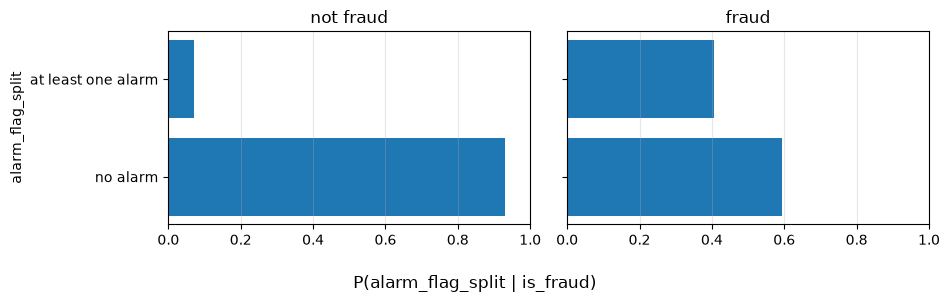

is_fraud               0.0   1.0
alarm_flag_split                
no alarm            640007  6931
at least one alarm   48264  4758
--------------------------------------------------
                   is_fraud  lift_to_base_rate
alarm_flag_split                              
at least one alarm    8.97%               5.37
no alarm              1.07%               0.64
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\alarm_flag_split\alarm_flag_split_fraud_rate.png


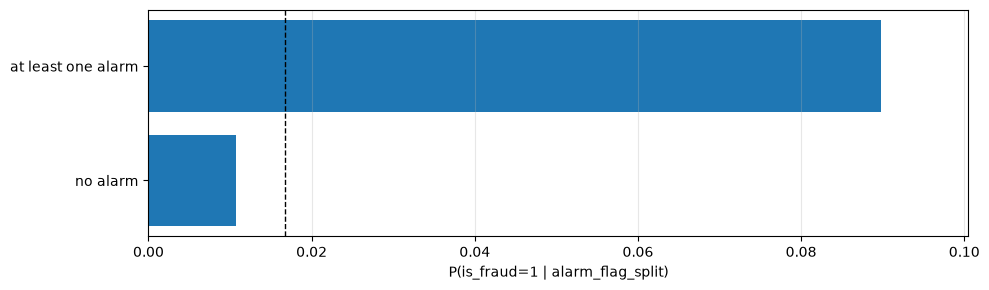

--------------------------------------------------
each flag inside the at-least-one slice
                        flag     n  share_of_alarm_rows  n_fraud  share_of_alarm_fraud  rate_when_true
         ip_country_mismatch 11312               0.2133   1866.0                0.3922          0.1650
                    used_vpn 23665               0.4463   1550.0                0.3258          0.0655
      is_foreign_transaction 12098               0.2282   1521.0                0.3197          0.1257
   billing_shipping_mismatch  9054               0.1708   1176.0                0.2472          0.1299
is_ai_generated_scam_attempt  2299               0.0434    350.0                0.0736          0.1522
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\tables\alarm_flag_split_each_flag.csv
--------------------------------------------------
how many of the five flags are on
is_fraud     0.0   1.0
row_0                 
0    

In [26]:
ALARM_FLAG_COLS = [
    IP_COUNTRY_MISMATCH_COL,
    IS_AI_GENERATED_SCAM_ATTEMPT_COL,
    BILLING_SHIPPING_MISMATCH_COL,
    IS_FOREIGN_TRANSACTION_COL,
    USED_VPN_COL,
]
ALARM_SPLIT_SECTION = "alarm_flag_split"
ALARM_SPLIT_COL = "alarm_flag_split"
ALARM_SPLIT_LABELS = {
    False: "no alarm",
    True: "at least one alarm",
}
ALARM_SPLIT_ORDER = ["no alarm", "at least one alarm"]

has_alarm_flag = train_df[ALARM_FLAG_COLS].any(axis=1)
alarm_split = has_alarm_flag.map(ALARM_SPLIT_LABELS)
alarm_split.name = ALARM_SPLIT_COL
base_rate = train_df[[TARGET]].mean(axis=0)
n_fraud_all = float(train_df[TARGET].sum())

occupancy = (
    train_df.groupby(alarm_split, observed=True)[TARGET]
    .agg(n="size", n_fraud="sum", rate="mean")
    .reindex(ALARM_SPLIT_ORDER)
)
occupancy["share_of_rows"] = occupancy["n"] / occupancy["n"].sum()
occupancy["share_of_fraud"] = occupancy["n_fraud"] / n_fraud_all
occupancy["lift_to_base_rate"] = occupancy["rate"] / float(base_rate.iloc[0])
print(occupancy.round(4))
print(DELIMITER_VALUE)

counts = pd.crosstab(train_df[TARGET], alarm_split)
share = counts.div(counts.sum(axis=1), axis=0).reindex(columns=ALARM_SPLIT_ORDER)
fig, axes = categorical_categorical.plot_conditional_share(
    share,
    feature=ALARM_SPLIT_COL,
    given=TARGET,
    given_labels=TARGET_GIVEN_LABELS,
)
plot_path = (
    get_script_plot_dir(NOTEBOOK_STEM, section=ALARM_SPLIT_SECTION)
    / "alarm_flag_split_given_fraud.png"
)
fig.savefig(plot_path, dpi=140)
print(share.round(4))
print(f"saved {plot_path}")
plt.show()

d_absolute = pd.crosstab(alarm_split, train_df[TARGET]).reindex(ALARM_SPLIT_ORDER)
d_relative = occupancy[["rate"]].rename(columns={"rate": TARGET})
d_lift = d_relative.div(base_rate, axis=1)
d_relative = d_relative.copy()
d_relative["lift_to_base_rate"] = d_lift.squeeze().round(2)
d_relative[TARGET] = (
    (d_relative[TARGET] * 100).round(2).map(lambda p: f"{p:.2f}%")
)
print(d_absolute)
print(DELIMITER_VALUE)
print(d_relative.sort_values(by="lift_to_base_rate", ascending=False))

rates = occupancy[["n", "n_fraud", "rate", "lift_to_base_rate"]].rename(
    columns={"n_fraud": "n_positive", "lift_to_base_rate": "lift"}
)
fig, ax = condition_categorical.plot_binary_rate(
    rates,
    feature=ALARM_SPLIT_COL,
    target=TARGET,
    positive=1,
    base_rate=float(base_rate.iloc[0]),
)
rate_plot = (
    get_script_plot_dir(NOTEBOOK_STEM, section=ALARM_SPLIT_SECTION)
    / "alarm_flag_split_fraud_rate.png"
)
fig.savefig(rate_plot, dpi=140)
print(f"saved {rate_plot}")
plt.show()

print(DELIMITER_VALUE)
print("each flag inside the at-least-one slice")
alarm_df = train_df.loc[has_alarm_flag]
n_fraud_alarm = float(alarm_df[TARGET].sum())
flag_rows = []
for col in ALARM_FLAG_COLS:
    on = alarm_df[col]
    flag_rows.append(
        {
            "flag": col,
            "n": int(on.sum()),
            "share_of_alarm_rows": float(on.mean()),
            "n_fraud": float(alarm_df.loc[on, TARGET].sum()),
            "share_of_alarm_fraud": (
                float(alarm_df.loc[on, TARGET].sum() / n_fraud_alarm)
            ),
            "rate_when_true": float(train_df.loc[train_df[col], TARGET].mean()),
        }
    )
flag_in_split = pd.DataFrame(flag_rows).sort_values(
    "share_of_alarm_fraud", ascending=False
)
print(flag_in_split.round(4).to_string(index=False))

n_alarm_flags = train_df[ALARM_FLAG_COLS].sum(axis=1)
n_flag_counts = pd.crosstab(n_alarm_flags, train_df[TARGET])
n_flag_share = n_flag_counts.div(n_flag_counts.sum(axis=1), axis=0)
print(DELIMITER_VALUE)
print("how many of the five flags are on")
print(n_flag_counts)
print(n_flag_share.round(4))


## Next cuts: combine atoms, keep them disjoint

Cut 1 only isolates the alarm union. The remaining $59\%$ of fraud still sits in $92\%$ of the rows. The next splits are intersections of the **cold atoms** in the dossier (risk floor / left tail, velocity left pile, `txn_count_last_24h = 0`, age at the floor, Biometric / PIN as a prior), formed so that the regions do not overlap, each with occupancy large enough to matter and $n_{\text{fraud}}$ on the order of $10$--$15$.

That combination step is the rest of the process. It is not a list of hand-picked pockets on the complement.

The cell below only records the pair count of cut 1 as two ranking slabs. Combinations are not computed here.

In [40]:
n_pos_alarm = float(train_df.loc[has_alarm_flag, TARGET].sum())
n_neg_alarm = float(has_alarm_flag.sum() - n_pos_alarm)
n_pos_no_alarm = float(train_df.loc[~has_alarm_flag, TARGET].sum())
n_neg_no_alarm = float((~has_alarm_flag).sum() - n_pos_no_alarm)
concordant_alarm_above = n_pos_alarm * n_neg_no_alarm
discordant_alarm_above = n_neg_alarm * n_pos_no_alarm
print(
    "cut 1 as two ranking slabs: alarm above no-alarm\n"
    f"alarm n={int(has_alarm_flag.sum())} n_fraud={int(n_pos_alarm)} "
    f"rate={n_pos_alarm / has_alarm_flag.sum():.4f}\n"
    f"no-alarm n={int((~has_alarm_flag).sum())} n_fraud={int(n_pos_no_alarm)} "
    f"rate={n_pos_no_alarm / (~has_alarm_flag).sum():.4f}\n"
    f"concordant={concordant_alarm_above:.0f} discordant={discordant_alarm_above:.0f} "
    f"net={concordant_alarm_above - discordant_alarm_above:.0f}"
)



cut 1 as two ranking slabs: alarm above no-alarm
alarm n=53022 n_fraud=4758 rate=0.0897
no-alarm n=646938 n_fraud=6931 rate=0.0107
concordant=3045153306 discordant=334517784 net=2710635522


## Fraud, Authentication Method and Merchant Category

n_fraud
merchant_category  Gift Cards  Crypto Exchange  Gaming  Electronics  \
auth_method                                                           
No Authentication         254              104     502          515   
3D Secure                 193              114     351          410   
OTP                       130               66     289          348   
PIN                        81               45     127          164   
Biometric                  32               16      42           64   

merchant_category  Streaming  Travel  Utilities  Healthcare  Fuel  \
auth_method                                                         
No Authentication        412     193        220         165   303   
3D Secure                261     155        123         123   187   
OTP                      215     117        132          98   140   
PIN                      126      51         72          55    89   
Biometric                 47      18         34          21    22   

merchant_c

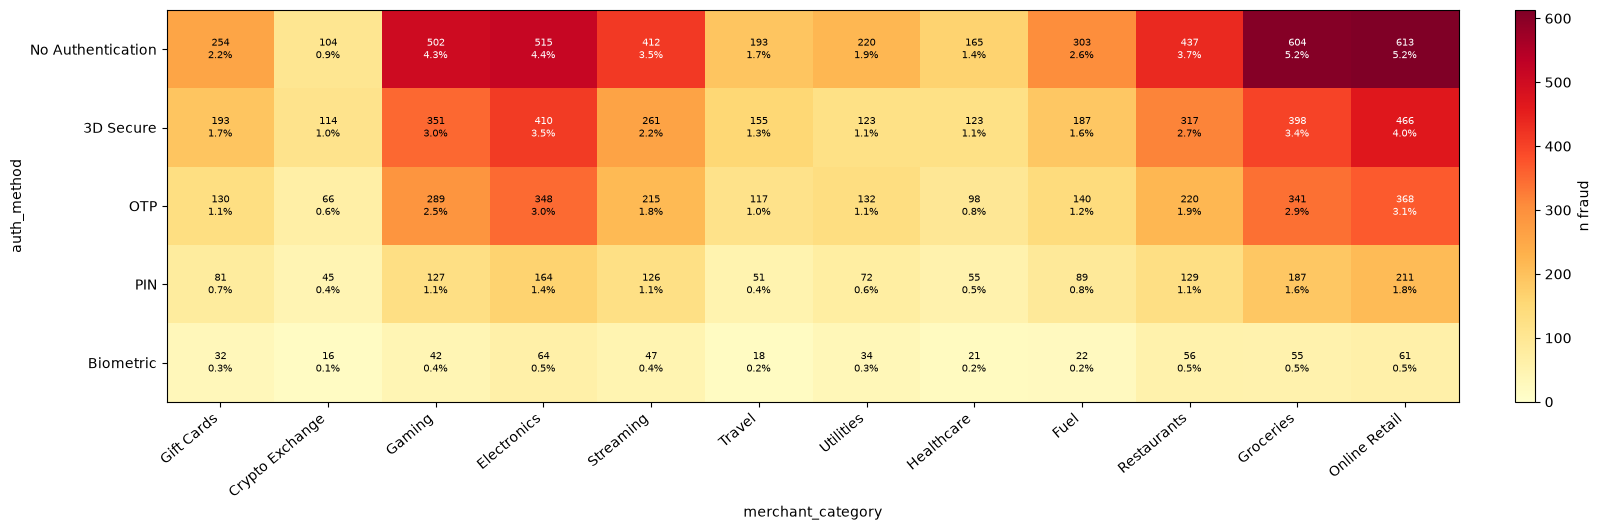

In [39]:
AUTH_MERCHANT_SECTION = "fraud_and_auth_method_and_merchant_category"

auth_order = (
    train_df.groupby(AUTH_METHOD_COL)[TARGET]
    .mean()
    .sort_values(ascending=False)
    .index
)
merchant_order = (
    train_df.groupby(MERCHANT_CATEGORY_COL)[TARGET]
    .mean()
    .sort_values(ascending=False)
    .index
)
n_all = pd.crosstab(
    train_df[AUTH_METHOD_COL],
    train_df[MERCHANT_CATEGORY_COL],
).reindex(index=auth_order, columns=merchant_order, fill_value=0)
n_fraud = pd.crosstab(
    train_df.loc[train_df[TARGET] == 1, AUTH_METHOD_COL],
    train_df.loc[train_df[TARGET] == 1, MERCHANT_CATEGORY_COL],
).reindex(index=auth_order, columns=merchant_order, fill_value=0)
share_of_fraud = n_fraud / n_fraud.to_numpy().sum()
rate = n_fraud.div(n_all.where(n_all > 0))
base_rate = float(train_df[TARGET].mean())
lift = rate / base_rate

joint = pd.concat(
    {
        "n": n_all.stack(),
        "n_fraud": n_fraud.stack(),
        "share_of_fraud": share_of_fraud.stack(),
        "rate": rate.stack(),
        "lift": lift.stack(),
    },
    axis=1,
).reset_index()
print("n_fraud")
print(n_fraud)
print(DELIMITER_VALUE)
print("share of fraud")
print(share_of_fraud.round(4))
print(DELIMITER_VALUE)
print("fraud rate")
print(rate.round(4))
print(DELIMITER_VALUE)
print(f"base_rate={base_rate:.4f}")

fig, ax = categorical_categorical.plot_count_and_share_heatmap(
    n_fraud,
    share_of_fraud,
    row=AUTH_METHOD_COL,
    col=MERCHANT_CATEGORY_COL,
)
plot_path = (
    get_script_plot_dir(NOTEBOOK_STEM, section=AUTH_MERCHANT_SECTION)
    / "auth_method_by_merchant_category_fraud.png"
)
fig.savefig(plot_path, dpi=140)
print(f"saved {plot_path}")
plt.show()


saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\money_and_meaningful_categorical_features\auth_method_by_merchant_category_fraud_rate.png


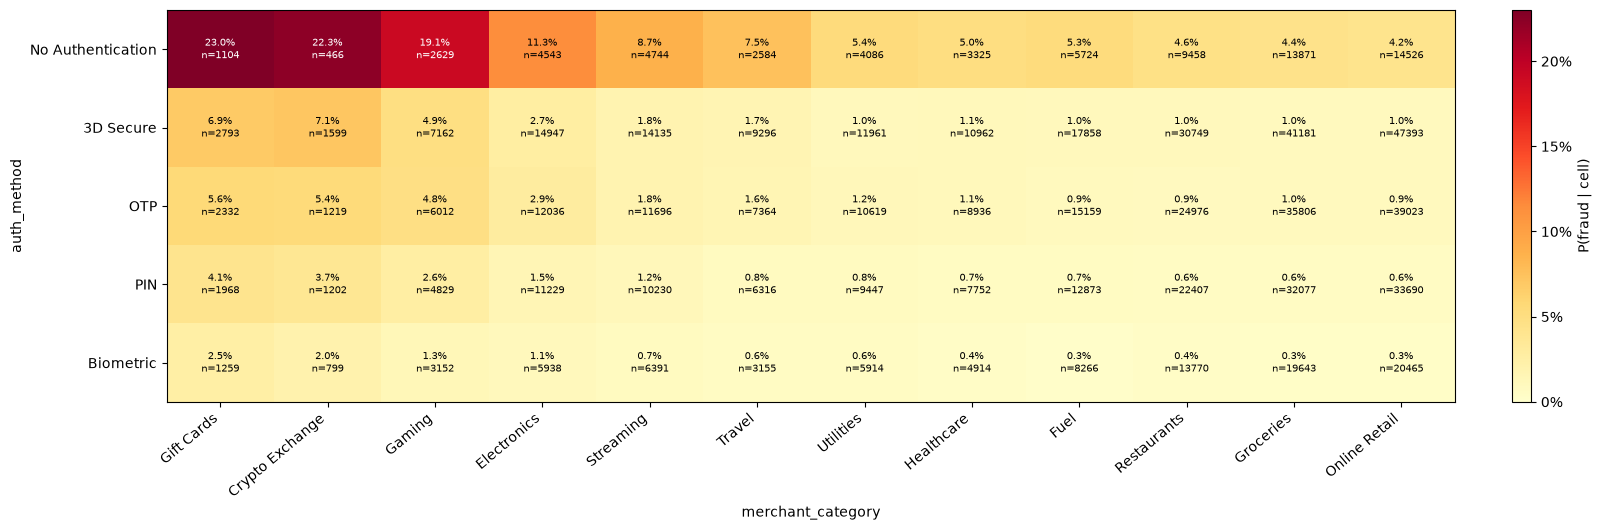

In [47]:
fig, ax = categorical_categorical.plot_rate_heatmap(
    rate,
    row=AUTH_METHOD_COL,
    col=MERCHANT_CATEGORY_COL,
    n=n_all,
)
plot_path = (
    get_script_plot_dir(NOTEBOOK_STEM, section=AUTH_MERCHANT_SECTION)
    / "auth_method_by_merchant_category_fraud_rate.png"
)
fig.savefig(plot_path, dpi=140)
print(f"saved {plot_path}")
plt.show()


# Fraud And Money Features

## CDF of money given fraud

If $F(x \mid \text{is\_fraud})$ barely moves with the label, that continuous money feature is a weak fraud signal on its own.

money features ['amount_usd', 'account_balance_usd']
--------------------------------------------------
amount_usd
             count    mean     std  min    50%     90%     95%      99%  \
is_fraud                                                                  
0.0       688271.0   79.37  204.17  1.0  27.21   81.83  541.12   936.79   
1.0        11689.0  110.50  255.81  1.0  31.18  456.30  612.85  1046.16   

              max  
is_fraud           
0.0       6872.69  
1.0       6078.29  
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\fraud_and_money_features\amount_usd_cdf_given_fraud.png x_scale=log


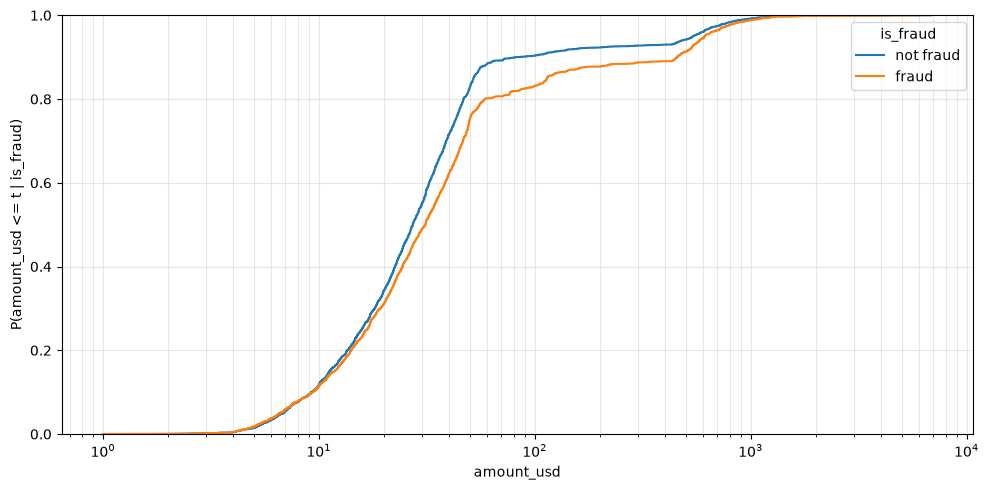

--------------------------------------------------
account_balance_usd
             count     mean      std    min      50%      90%      95%  \
is_fraud                                                                 
0.0       688271.0  2064.52  3403.99  58.25  1382.74  4020.76  4861.18   
1.0        11689.0  2093.09  3164.44  58.89  1396.00  4202.61  4908.24   

              99%       max  
is_fraud                     
0.0       9082.81  99701.39  
1.0       9082.81  88566.00  
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\fraud_and_money_features\account_balance_usd_cdf_given_fraud.png x_scale=log


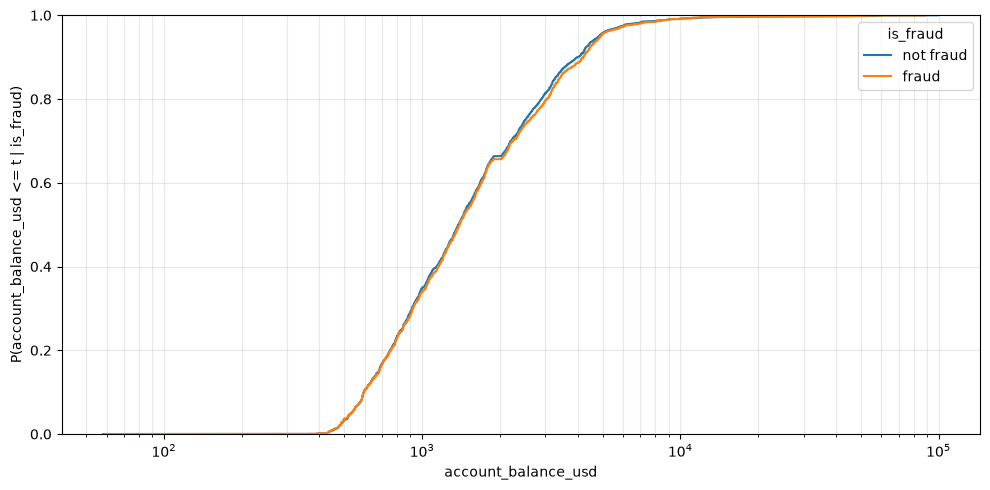

In [44]:
# P(x <= t | is_fraud) for every continuous money column.
# money = numeric columns denominated in usd. long-tailed, so x is log when x > 0.

import numpy as np

AMOUNT_COL = "amount_usd"
MONEY_SECTION = "fraud_and_money_features"
MONEY_COLS = [
    col
    for col in train_df.columns
    if col.endswith("_usd") and pd.api.types.is_numeric_dtype(train_df[col])
]
print("money features", MONEY_COLS)

for money_col in MONEY_COLS:
    print(DELIMITER_VALUE)
    print(money_col)
    print(
        train_df.groupby(TARGET)[money_col]
        .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
        .round(2)
    )
    cdf_parts = []
    for level, part in train_df.groupby(TARGET, sort=True):
        x = np.sort(part[money_col].to_numpy())
        cdf = np.arange(1, len(x) + 1) / len(x)
        cdf_parts.append(
            pd.DataFrame({money_col: x, "cdf": cdf, TARGET: level})
        )
    curves = pd.concat(cdf_parts, ignore_index=True)
    x_scale = "log" if bool((curves[money_col] > 0).all()) else "linear"
    fig, ax = categorical_numeric.plot_conditional_cdf(
        curves,
        x=money_col,
        cdf="cdf",
        group=TARGET,
        x_scale=x_scale,
        group_labels=TARGET_GIVEN_LABELS,
    )
    plot_path = (
        get_script_plot_dir(NOTEBOOK_STEM, section=MONEY_SECTION)
        / f"{money_col}_cdf_given_fraud.png"
    )
    fig.savefig(plot_path, dpi=140)
    print(f"saved {plot_path} x_scale={x_scale}")
    plt.show()


It seems that frauds do not discriminate between poor and rich. The account balance at the transaction time does not seem to contain any fraud signal. 

Let's try to dig a bit deeper, however. The ratio might actually be a more interesting indicator: the percentage of this transaction with respect to the account's balance.


             count    mean     std     min     50%     90%     95%     99%  \
is_fraud                                                                     
0.0       688271.0  0.0663  0.2047  0.0000  0.0185  0.0857  0.3035  1.0064   
1.0        11689.0  0.0920  0.2496  0.0001  0.0210  0.1980  0.5148  1.1541   

              max  
is_fraud           
0.0       14.6098  
1.0        6.9807  
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\fraud_and_money_features\amount_over_balance_cdf_given_fraud.png x_scale=log


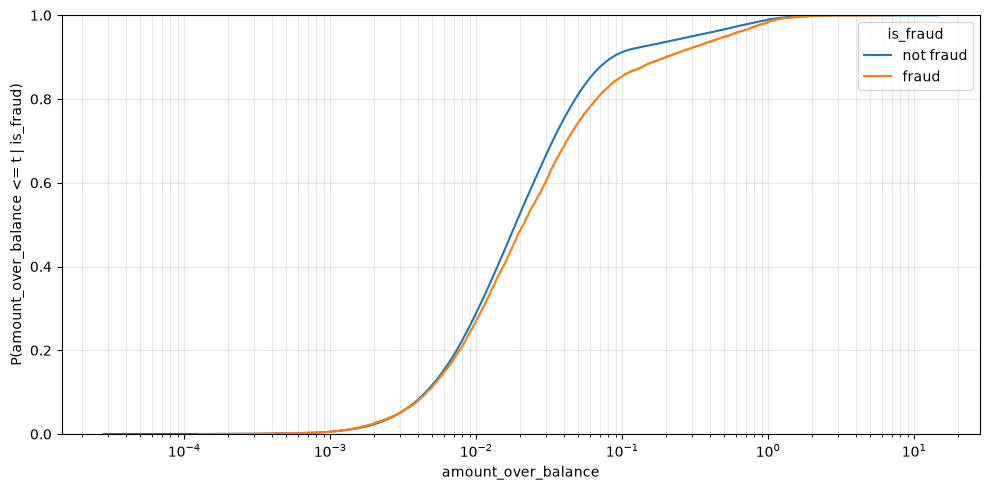

In [45]:
# amount / account_balance: share of the account spent in this transaction.

RATIO_COL = "amount_over_balance"
train_df[RATIO_COL] = train_df[AMOUNT_COL] / train_df["account_balance_usd"]
print(
    train_df.groupby(TARGET)[RATIO_COL]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(4)
)

cdf_parts = []
for level, part in train_df.groupby(TARGET, sort=True):
    x = np.sort(part[RATIO_COL].to_numpy())
    cdf = np.arange(1, len(x) + 1) / len(x)
    cdf_parts.append(
        pd.DataFrame({RATIO_COL: x, "cdf": cdf, TARGET: level})
    )
ratio_cdf = pd.concat(cdf_parts, ignore_index=True)
x_scale = "log" if bool((ratio_cdf[RATIO_COL] > 0).all()) else "linear"
fig, ax = categorical_numeric.plot_conditional_cdf(
    ratio_cdf,
    x=RATIO_COL,
    cdf="cdf",
    group=TARGET,
    x_scale=x_scale,
    group_labels=TARGET_GIVEN_LABELS,
)
plot_path = (
    get_script_plot_dir(NOTEBOOK_STEM, section=MONEY_SECTION)
    / "amount_over_balance_cdf_given_fraud.png"
)
fig.savefig(plot_path, dpi=140)
print(f"saved {plot_path} x_scale={x_scale}")
plt.show()


## Money and meaningful cateogorical features


Before giving up on the money features, It might be interesting to try to relativize the quantity. 

$100$ might not mean much when spent on travel. However, it might be quite suspicious when spent on Fuel for example. The same goes for the ratio.  

The same intuition goes. $100$ used authenticated with biometrics might not be problematic. $100$ usd authenticated with OTP is. 

A more general conceptualization is: 

$$
P(amount | \text{authentication\_method}) <= threshold \implies \text{high fraud probability}
$$ 

Let's see if the data has something to tell us in this regard

In [34]:
# so whether the channel is ATM, contactless, In-app, Online or POS we have almost the exact same distribution of the authentication method. Maybe discard channel ? 

# let's try to revisit the fraud and auth_method analysis

intersection_cols = ["auth_method", "merchant_category"]

for col in intersection_cols:    
    d = train_df[[col, TARGET]].pivot_table(index=TARGET, values=col, columns=col, aggfunc="count")
    # print(d)
    # print("-" * 20)
    d_total = d.sum(axis=1)
    d_share = d.div(d_total, axis=0)
    print(d_share)
    print("-" * 20)

    # interestingly: only 4% of the fradulent transactions go through Biometric authentication
    # 36% through No authentication (expected it to be highter)

auth_method  3D Secure  Biometric  No Authentication       OTP       PIN
is_fraud                                                                
0.0           0.300664   0.135409           0.091153  0.250939  0.221836
1.0           0.265036   0.040038           0.369749  0.210796  0.114381
--------------------
merchant_category  Crypto Exchange  Electronics      Fuel    Gaming  \
is_fraud                                                              
0.0                       0.007177     0.068566  0.085924  0.032651   
1.0                       0.029515     0.128411  0.063393  0.112157   

merchant_category  Gift Cards  Groceries  Healthcare  Online Retail  \
is_fraud                                                              
0.0                  0.012736   0.204851    0.051472       0.222845   
1.0                  0.059030   0.135598    0.039524       0.147061   

merchant_category  Restaurants  Streaming    Travel  Utilities  
is_fraud                                            

In [12]:
for col in intersection_cols:    
    d = train_df[[col, TARGET]].pivot_table(index=col, values=TARGET, columns=TARGET, aggfunc="count")
    # print(d)
    # print("-" * 20)
    d_total = d.sum(axis=1)
    d_share = d.div(d_total, axis=0)
    d_share = d_share.rename(columns={1.0: "fraud", 0.0: "not_fraud"})
    print(d_share.sort_values(by="fraud", ascending=False).round(4))
    print("-" * 20)

is_fraud           not_fraud   fraud
auth_method                         
No Authentication     0.9356  0.0644
3D Secure             0.9853  0.0147
OTP                   0.9859  0.0141
PIN                   0.9913  0.0087
Biometric             0.9950  0.0050
--------------------
is_fraud           not_fraud   fraud
merchant_category                   
Gift Cards            0.9270  0.0730
Crypto Exchange       0.9347  0.0653
Gaming                0.9449  0.0551
Electronics           0.9692  0.0308
Streaming             0.9775  0.0225
Travel                0.9814  0.0186
Utilities             0.9862  0.0138
Healthcare            0.9871  0.0129
Fuel                  0.9876  0.0124
Restaurants           0.9886  0.0114
Groceries             0.9889  0.0111
Online Retail         0.9889  0.0111
--------------------


In [13]:
# the device_type is a bit more interesting. 

device_type_str = "device_type"

print(train_df[device_type_str].value_counts(normalize=True))

# we can probably simplify to a few possible combinations
# pos_atm, computer, personal_device. The authentication should be dependent on the device type. I don't expect Biometric with ATM / POS. That might explain why PIN has a very low percentage of fradulent transactions

train_df_2 = train_df.copy()
def transform_device_type(org_device_type: str):
    if "pos" in org_device_type.lower() or "atm" in org_device_type.lower():
        return "pos_atm"
    elif org_device_type.lower() in ["mac", "windows pc"]:
        return "computer"
    if "phone" in org_device_type.lower() or org_device_type.lower() in ["tablet", "smart watch"]:
        return "personal_device"

    raise ValueError(f"Unknown device type: {org_device_type}")
train_df_2[device_type_str] = train_df_2[device_type_str].apply(transform_device_type)
print(train_df_2[device_type_str].value_counts(normalize=True))

device_type
Android Phone    0.339239
iPhone           0.235286
POS Terminal     0.161776
Windows PC       0.115627
Mac              0.048536
Tablet           0.039557
Smart Watch      0.030153
ATM Machine      0.029826
Name: proportion, dtype: float64
device_type
personal_device    0.644235
pos_atm            0.191602
computer           0.164162
Name: proportion, dtype: float64


In [14]:
# let's see the interaction between the device type and the authentication method

d = train_df_2[[device_type_str, auth_method_str]].pivot_table(index=device_type_str, columns=auth_method_str, values=auth_method_str, aggfunc="count") 
d_total = d.sum(axis=1)
d_share = d.div(d_total, axis=0).round(4) 
print(d_share )

# this quick analysis already suggests that the device type grouping is good and once again the authentication method is completely indepdent of the transaction source (channel / device type)


auth_method      3D Secure  Biometric  No Authentication     OTP     PIN
device_type                                                             
computer            0.3049     0.1322             0.0949  0.2502  0.2178
personal_device     0.2981     0.1337             0.0959  0.2495  0.2229
pos_atm             0.3026     0.1355             0.0963  0.2531  0.2125


# IP, VPN, distance from home

In [15]:
# distance and ip
# question: is ip_country_mismatch (especially without vpn) a coarsening of
# distance_from_home_km, or another independent generator flag?
#
# if it is a coarsening of distance, mismatch-without-vpn should sit at large km
# and P(mismatch) should rise with distance. if it is an artifact, the four
# groups occupy the same distance range.

import numpy as np
import matplotlib.pyplot as plt
from ccf_ml.file_utils import get_script_plot_dir, get_script_table_dir

DISTANCE_COL = "distance_from_home_km"
MISMATCH_COL = "ip_country_mismatch"
VPN_COL = "used_vpn"

# 1: no_mismatch, no_vpn
# 2: mismatch, no_vpn
# 3: no_mismatch, vpn
# 4: mismatch, vpn
IP_VPN_LABELS = {
    1: "no_mismatch, no_vpn",
    2: "mismatch, no_vpn",
    3: "no_mismatch, vpn",
    4: "mismatch, vpn",
}
train_df["ip_vpn_code"] = (
    1
    + train_df[MISMATCH_COL].astype(int)
    + 2 * train_df[VPN_COL].astype(int)
)

d = pd.crosstab(train_df[MISMATCH_COL], train_df[VPN_COL], margins=True)
print("ip_country_mismatch x used_vpn")
print(d)
print(pd.crosstab(train_df[MISMATCH_COL], train_df[VPN_COL], normalize="all").round(4))
print("-" * 20)

print("distance_from_home_km by ip/vpn group")
print(
    train_df.groupby("ip_vpn_code")[DISTANCE_COL]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99])
    .rename(index=IP_VPN_LABELS)
    .round(2)
)

ip_country_mismatch x used_vpn
used_vpn              False   True     All
ip_country_mismatch                       
False                665571  23077  688648
True                  10724    588   11312
All                  676295  23665  699960
used_vpn              False   True 
ip_country_mismatch                
False                0.9509  0.0330
True                 0.0153  0.0008
--------------------
distance_from_home_km by ip/vpn group
                        count   mean    std   min   25%    50%    75%    90%  \
ip_vpn_code                                                                    
no_mismatch, no_vpn  665571.0  13.58  11.61  0.00  4.44  10.22  19.74  31.42   
mismatch, no_vpn      10724.0  13.63  11.69  0.01  4.41  10.27  19.72  31.78   
no_mismatch, vpn      23077.0  13.66  11.72  0.01  4.37  10.22  20.13  31.56   
mismatch, vpn           588.0  13.34  11.43  0.03  4.45  10.42  19.30  29.44   

                       99%    max  
ip_vpn_code                       

In [16]:
# coarsening test: P(mismatch) and P(vpn) by distance decile.
# a real country-mismatch flag should become more common as km grows.

dist_bin = pd.qcut(train_df[DISTANCE_COL], 10)
decile = train_df.groupby(dist_bin, observed=True).agg(
    n=(DISTANCE_COL, "size"),
    mean_distance=(DISTANCE_COL, "mean"),
    p_mismatch=(MISMATCH_COL, "mean"),
    p_vpn=(VPN_COL, "mean"),
    p_foreign=("is_foreign_transaction", "mean"),
)
print(decile.round(4))
print("-" * 20)
print("P(mismatch | vpn)")
print(train_df.groupby(VPN_COL)[MISMATCH_COL].mean().round(4))
print("P(foreign | ip_vpn_code)")
print(
    train_df.groupby("ip_vpn_code")["is_foreign_transaction"]
    .mean()
    .rename(index=IP_VPN_LABELS)
    .round(4)
)

                           n  mean_distance  p_mismatch   p_vpn  p_foreign
distance_from_home_km                                                     
(-0.001, 1.65]         70407         0.7769      0.0166  0.0335     0.0177
(1.65, 3.33]           69742         2.4814      0.0160  0.0347     0.0167
(3.33, 5.33]           70560         4.3829      0.0160  0.0333     0.0172
(5.33, 7.59]           69654         6.4209      0.0157  0.0340     0.0172
(7.59, 10.22]          69976         8.9088      0.0163  0.0334     0.0179
(10.22, 13.51]         69723        11.8592      0.0165  0.0336     0.0174
(13.51, 17.49]         69947        15.5224      0.0158  0.0334     0.0174
(17.49, 22.73]         70069        19.9442      0.0165  0.0328     0.0165
(22.73, 31.43]         70206        26.7993      0.0156  0.0349     0.0173
(31.43, 57.93]         69676        38.9164      0.0165  0.0344     0.0176
--------------------
P(mismatch | vpn)
used_vpn
False    0.0159
True     0.0248
Name: ip_country_mis

In [18]:
# scatter: distance on x, the four ip/vpn states on y.
# 700k points would bury the rare groups, so take up to 3000 rows per code.
# y is jittered so overplotting is visible. if mismatch coarsens distance,
# row 2 should sit to the right of row 1.

# rng = np.random.default_rng(0)
# max_per_code = 3000
# samples = [None] * 4

# for i, code in enumerate((1, 2, 3, 4)):
#     part = train_df.loc[train_df["ip_vpn_code"].eq(code), [DISTANCE_COL, "ip_vpn_code"]]
#     n_take = min(max_per_code, len(part))

# out_path = get_script_table_dir("eda_1_notebook") / "distance_ip_vpn_decile.csv"
# decile.to_csv(out_path)
# print(f"saved {out_path}")

# vis = pd.concat(samples, ignore_index=True)
# y_jitter = vis["ip_vpn_code"].to_numpy() + rng.uniform(-0.18, 0.18, size=len(vis))

# fig, ax = plt.subplots(figsize=(11, 5))
# ax.scatter(vis[DISTANCE_COL], y_jitter, s=8, alpha=0.22, linewidths=0, c="#4c78a8")
# ax.set_yticks(list(IP_VPN_LABELS))
# ax.set_yticklabels([IP_VPN_LABELS[k] for k in IP_VPN_LABELS])
# ax.set_xlabel(DISTANCE_COL)
# ax.set_ylabel("ip / vpn state")
# ax.set_title("distance_from_home_km vs ip_country_mismatch x used_vpn")
# ax.set_ylim(0.5, 4.5)
# fig.tight_layout()

# out_path = (
#     get_script_plot_dir(
#         "eda_1_notebook", section="ip_vpn_distance_from_home"
#     )
#     / "distance_ip_vpn_scatter.png"
# )
# if not out_path.exists():
#     fig.savefig(out_path, dpi=140)

# print(f"saved {out_path}")
# plt.show()

In [19]:
# not the coarsening question, but the same 4 groups vs fraud.
# if the flags are independent of distance they can still be a strong signal.

d = train_df.pivot_table(
    index="ip_vpn_code",
    columns=TARGET,
    values=DISTANCE_COL,
    aggfunc="count",
)
d_share = d.div(d.sum(axis=1), axis=0).rename(columns={0.0: "not_fraud", 1.0: "fraud"})
d_share = d_share.rename(index=IP_VPN_LABELS)
print(d_share.round(4))
print(d.rename(index=IP_VPN_LABELS))

is_fraud             not_fraud   fraud
ip_vpn_code                           
no_mismatch, no_vpn     0.9872  0.0128
mismatch, no_vpn        0.8500  0.1500
no_mismatch, vpn        0.9440  0.0560
mismatch, vpn           0.5629  0.4371
is_fraud                0.0   1.0
ip_vpn_code                      
no_mismatch, no_vpn  657041  8530
mismatch, no_vpn       9115  1609
no_mismatch, vpn      21784  1293
mismatch, vpn           331   257


# Beyond obvious flags

In [20]:
# 16 combinations of the four named alarms. 0000 is the bulk of the rows
# and still most of the fraud mass, at a much lower rate.

FLAG_COLS = [
    "ip_country_mismatch",
    "used_vpn",
    "is_foreign_transaction",
    "billing_shipping_mismatch",
]
n_fraud_all = train_df[TARGET].sum()
flag_pack = train_df.groupby(FLAG_COLS)[TARGET].agg(
    n="size", n_fraud="sum", fraud_rate="mean"
)
flag_pack["share_of_rows"] = flag_pack["n"] / flag_pack["n"].sum()
flag_pack["share_of_fraud"] = flag_pack["n_fraud"] / n_fraud_all
flag_pack = flag_pack.sort_values("n_fraud", ascending=False)
print(flag_pack.round(4))
print("-" * 20)

clean_mask = train_df[FLAG_COLS].eq(False).all(axis=1)
print("0000 vs at least one flag")
print(
    train_df.groupby(clean_mask)[TARGET]
    .agg(n="size", n_fraud="sum", fraud_rate="mean")
    .rename(index={True: "0000", False: "at_least_one_flag"})
)

                                                                                    n  \
ip_country_mismatch used_vpn is_foreign_transaction billing_shipping_mismatch           
False               False    False                  False                      648984   
                    True     False                  False                       22436   
                    False    False                  True                         8368   
True                False    False                  False                        7254   
                             True                   False                        3237   
False               False    True                   False                        8080   
True                True     False                  False                         382   
                             True                   False                         190   
False               True     False                  True                          293   
                     

In [21]:
# leftover fraud inside 0000. auth_method first, then anything else that still moves.

clean_df = train_df.loc[clean_mask]
clean_base = clean_df[TARGET].mean()
print(
    f"0000 n={len(clean_df)} fraud={int(clean_df[TARGET].sum())} "
    f"rate={clean_base:.4f} share_of_all_fraud={clean_df[TARGET].sum() / n_fraud_all:.3f}"
)

clean_indicator_cols = [
    "auth_method",
    "cvv_retry_count",
    "is_new_merchant",
    "merchant_category",
    "is_ai_generated_scam_attempt",
    "prior_disputes",
]
for col in clean_indicator_cols:
    d = pd.crosstab(clean_df[col], clean_df[TARGET])
    d = d.reindex(columns=[0.0, 1.0], fill_value=0)
    d_share = d.div(d.sum(axis=1), axis=0).rename(columns={0.0: "not_fraud", 1.0: "fraud"})
    d_share["lift_vs_0000"] = d_share["fraud"] / clean_base
    d_share["n"] = d.sum(axis=1)
    d_share["n_fraud"] = d[1.0]
    d_share["share_of_0000_fraud"] = d_share["n_fraud"] / clean_df[TARGET].sum()
    print(d_share.sort_values("fraud", ascending=False).round(4))
    print("-" * 20)

0000 n=648984 fraud=7145 rate=0.0110 share_of_all_fraud=0.611
is_fraud           not_fraud   fraud  lift_vs_0000       n  n_fraud  \
auth_method                                                           
No Authentication     0.9548  0.0452        4.1060   61586     2784   
3D Secure             0.9907  0.0093        0.8468  194678     1815   
OTP                   0.9908  0.0092        0.8317  162612     1489   
PIN                   0.9945  0.0055        0.4962  142957      781   
Biometric             0.9968  0.0032        0.2877   87151      276   

is_fraud           share_of_0000_fraud  
auth_method                             
No Authentication               0.3896  
3D Secure                       0.2540  
OTP                             0.2084  
PIN                             0.1093  
Biometric                       0.0386  
--------------------
is_fraud         not_fraud   fraud  lift_vs_0000       n  n_fraud  \
cvv_retry_count                                                

In [22]:
# numerics that still move inside 0000, and columns that stay flat.

moving_numeric_cols = [
    "merchant_risk_score",
    "velocity_score",
    "customer_age",
    "txn_count_last_24h",
    "amount_usd",
]
for col in moving_numeric_cols:
    if col == "txn_count_last_24h":
        key = clean_df[col]
    else:
        key = pd.qcut(clean_df[col], 10, duplicates="drop")
    d = clean_df.groupby(key, observed=True)[TARGET].agg(n="size", n_fraud="sum", fraud="mean")
    d["lift_vs_0000"] = d["fraud"] / clean_base
    print(col)
    print(d.round(4))
    print("-" * 20)

print("flat in 0000: channel / device / distance")
for col in ["channel", "device_type"]:
    d = pd.crosstab(clean_df[col], clean_df[TARGET])
    d_share = d.div(d.sum(axis=1), axis=0).rename(columns={0.0: "not_fraud", 1.0: "fraud"})
    print(d_share.sort_values("fraud", ascending=False).round(4))
    print("-" * 20)
print(clean_df.groupby(TARGET)["distance_from_home_km"].describe().round(2))

merchant_risk_score
                         n  n_fraud   fraud  lift_vs_0000
merchant_risk_score                                      
(-0.001, 19.9]       65082     67.0  0.0010        0.0935
(19.9, 24.6]         64981    111.0  0.0017        0.1552
(24.6, 28.1]         66675    273.0  0.0041        0.3719
(28.1, 31.2]         64727    253.0  0.0039        0.3550
(31.2, 34.1]         63670    339.0  0.0053        0.4836
(34.1, 37.2]         65791    621.0  0.0094        0.8573
(37.2, 40.6]         63559    818.0  0.0129        1.1690
(40.6, 45.0]         65559    885.0  0.0135        1.2261
(45.0, 51.5]         64336   1327.0  0.0206        1.8735
(51.5, 100.0]        64604   2451.0  0.0379        3.4460
--------------------
velocity_score
                    n  n_fraud   fraud  lift_vs_0000
velocity_score                                      
(-0.001, 4.1]   65528     52.0  0.0008        0.0721
(4.1, 9.5]      65326    241.0  0.0037        0.3351
(9.5, 13.1]     64397    256.0  0.00

# Amount CDF by authentication method

                      count   mean     std  min    50%     90%     95%  \
auth_method                                                              
3D Secure          210036.0  82.73  209.37  1.0  27.45  105.26  554.67   
Biometric           93666.0  72.65  185.42  1.0  26.91   63.61  497.17   
No Authentication   67060.0  76.76  203.26  1.0  27.28   72.56  528.94   
OTP                175178.0  79.59  208.58  1.0  27.29   86.37  541.12   
PIN                154020.0  82.13  207.62  1.0  27.12  101.56  559.74   

                      99%      max  
auth_method                         
3D Secure          953.15  6872.69  
Biometric          874.34  6058.54  
No Authentication  913.96  6872.69  
OTP                935.34  6872.69  
PIN                942.25  6153.69  
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\amount_cdf_by_auth_method.png


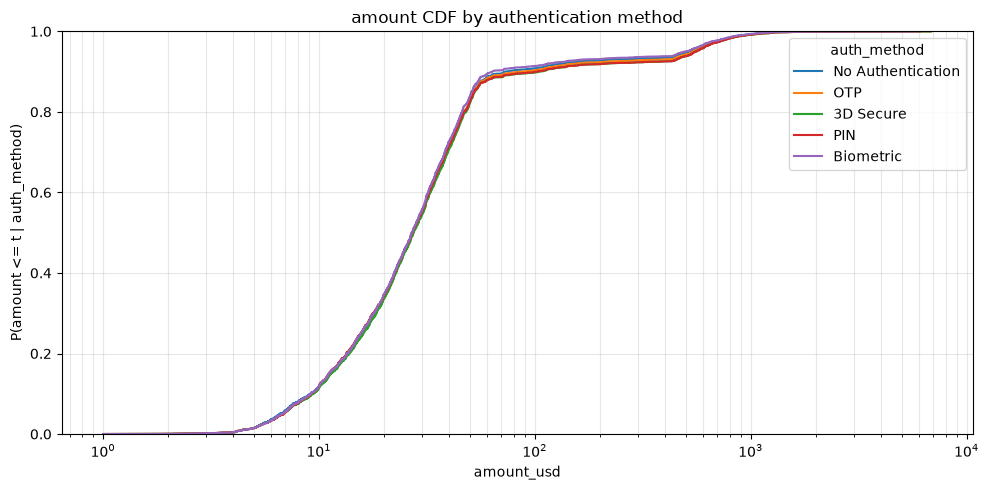

In [23]:
# P(amount_usd <= t | auth_method). amount is heavy-tailed, so the x-axis is log.

AMOUNT_COL = "amount_usd"
auth_values = [
    "No Authentication",
    "OTP",
    "3D Secure",
    "PIN",
    "Biometric",
]

print(
    train_df.groupby(auth_method_str)[AMOUNT_COL]
    .describe(percentiles=[0.5, 0.9, 0.95, 0.99])
    .round(2)
)

fig, ax = plt.subplots(figsize=(10, 5))
for auth in auth_values:
    amounts = np.sort(
        train_df.loc[train_df[auth_method_str].eq(auth), AMOUNT_COL].to_numpy()
    )
    cdf = np.arange(1, len(amounts) + 1) / len(amounts)
    ax.plot(amounts, cdf, label=auth, drawstyle="steps-post")

ax.set_xscale("log")
ax.set_xlabel(AMOUNT_COL)
ax.set_ylabel("P(amount <= t | auth_method)")
ax.set_title("amount CDF by authentication method")
ax.set_ylim(0, 1)
ax.legend(title=auth_method_str)
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()

out_path = (
    get_script_plot_dir(
        "eda_1_notebook", section="amount_cdf_by_authentication_method"
    )
    / "amount_cdf_by_auth_method.png"
)

if not out_path.exists():
    fig.savefig(out_path, dpi=140)

print(f"saved {out_path}")
plt.show()

# Auth mix for amount >= t

unique amount_usd 13387
unique amount_int 1288
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\tables\auth_mix_ge_amount.csv shape=(5, 1288)
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\tables\auth_mix_ge_amount_n.csv
point-biserial corr(amount_int, auth dummy)
  No Authentication    -0.0050
  OTP                  -0.0008
  3D Secure            +0.0090
  PIN                  +0.0058
  Biometric            -0.0139
mix among amount_int >= t
        No Authentication     OTP  3D Secure     PIN  Biometric      n_ge
t                                                                        
1.0                0.0958  0.2503     0.3001  0.2200     0.1338  699960.0
27.0               0.0960  0.2509     0.3022  0.2186     0.1323  362918.0
50.0               0.0951  0.2494     0.3090  0.2221     0.1244  126096.0
90.0               0.0906  0.2492     0.3137  

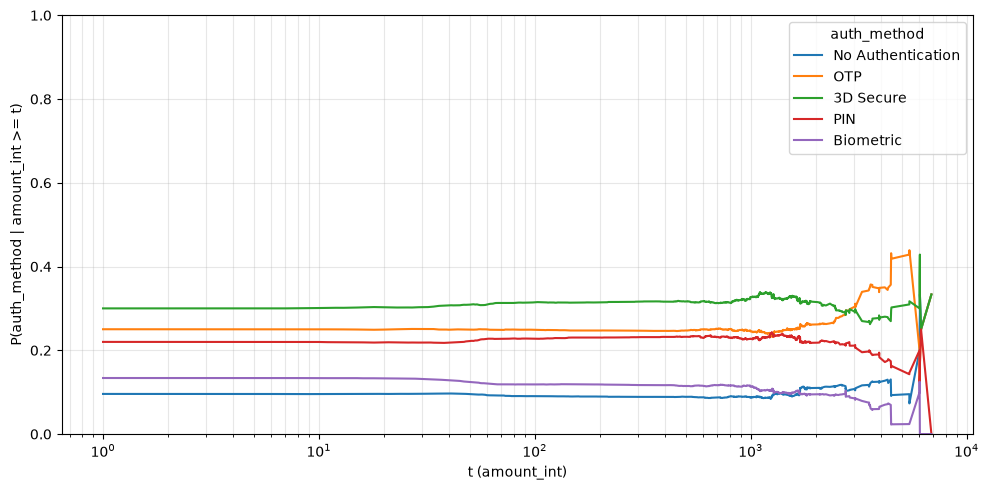

In [24]:
# P(auth_method | amount_int >= t): mix among tickets at least t.
# as t rises this is only the expensive tail, so a real amount-auth rule can show up.
# n_ge is how many rows remain; the far right is noisy.

NOTEBOOK_STEM = "eda_1_notebook"
tables_dir = get_script_table_dir(NOTEBOOK_STEM)
plots_dir = get_script_plot_dir(
    NOTEBOOK_STEM, section="auth_mix_ge_amount"
)
card_type_str = "card_type"
train_df["amount_int"] = train_df[AMOUNT_COL].round().astype("int64")
print("unique amount_usd", train_df[AMOUNT_COL].nunique())
print("unique amount_int", train_df["amount_int"].nunique())


def auth_mix_from_amount(frame: pd.DataFrame) -> pd.DataFrame:
    """P(auth_method | amount_int >= t). Index is t. Includes n_ge."""
    ordered = frame[["amount_int", auth_method_str]].sort_values(
        "amount_int", kind="mergesort"
    )
    dummies = pd.get_dummies(ordered[auth_method_str], dtype="int64")
    for auth in auth_values:
        if auth not in dummies.columns:
            dummies[auth] = 0
    dummies = dummies.loc[:, auth_values]
    running = dummies.iloc[::-1].cumsum().iloc[::-1]
    n_ge = np.arange(len(ordered), 0, -1)
    mix = running.div(n_ge, axis=0)
    mix["amount_int"] = ordered["amount_int"].to_numpy()
    mix["n_ge"] = n_ge
    return mix.groupby("amount_int", sort=True).first()


mix_ge = auth_mix_from_amount(train_df)
wide_ge = mix_ge[auth_values].T
wide_ge.index.name = auth_method_str
wide_ge_path = tables_dir / "auth_mix_ge_amount.csv"
wide_ge.to_csv(wide_ge_path)
n_ge_path = tables_dir / "auth_mix_ge_amount_n.csv"
mix_ge[["n_ge"]].to_csv(n_ge_path)
print(f"saved {wide_ge_path} shape={wide_ge.shape}")
print(f"saved {n_ge_path}")

print("point-biserial corr(amount_int, auth dummy)")
for auth in auth_values:
    dummy = train_df[auth_method_str].eq(auth).astype("int64")
    corr = train_df["amount_int"].corr(dummy)
    print(f"  {auth:20s} {corr:+.4f}")

tail_cutoffs = [1, 27, 50, 90, 200, 500, 1000]
print("mix among amount_int >= t")
tail_print = [None] * len(tail_cutoffs)
for i, t in enumerate(tail_cutoffs):
    ge_index = mix_ge.index[mix_ge.index >= t]
    if len(ge_index) == 0:
        continue
    row = mix_ge.loc[ge_index[0], auth_values + ["n_ge"]].copy()
    row["t"] = int(ge_index[0])
    tail_print[i] = row
tail_df = pd.DataFrame([r for r in tail_print if r is not None]).set_index("t")
print(tail_df.round(4))

fig, ax = plt.subplots(figsize=(10, 5))
for auth in auth_values:
    ax.plot(mix_ge.index.to_numpy(), mix_ge[auth].to_numpy(), label=auth)
ax.set_xscale("log")
ax.set_xlabel("t (amount_int)")
ax.set_ylabel("P(auth_method | amount_int >= t)")
ax.set_ylim(0, 1)
ax.legend(title=auth_method_str)
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
mix_ge_plot_path = plots_dir / "auth_mix_ge_amount.png"
fig.savefig(mix_ge_plot_path, dpi=140)
print(f"saved {mix_ge_plot_path}")
plt.show()

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\tables\auth_mix_ge_amount_by_card_type.csv
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\auth_mix_ge_amount_by_card_type.png


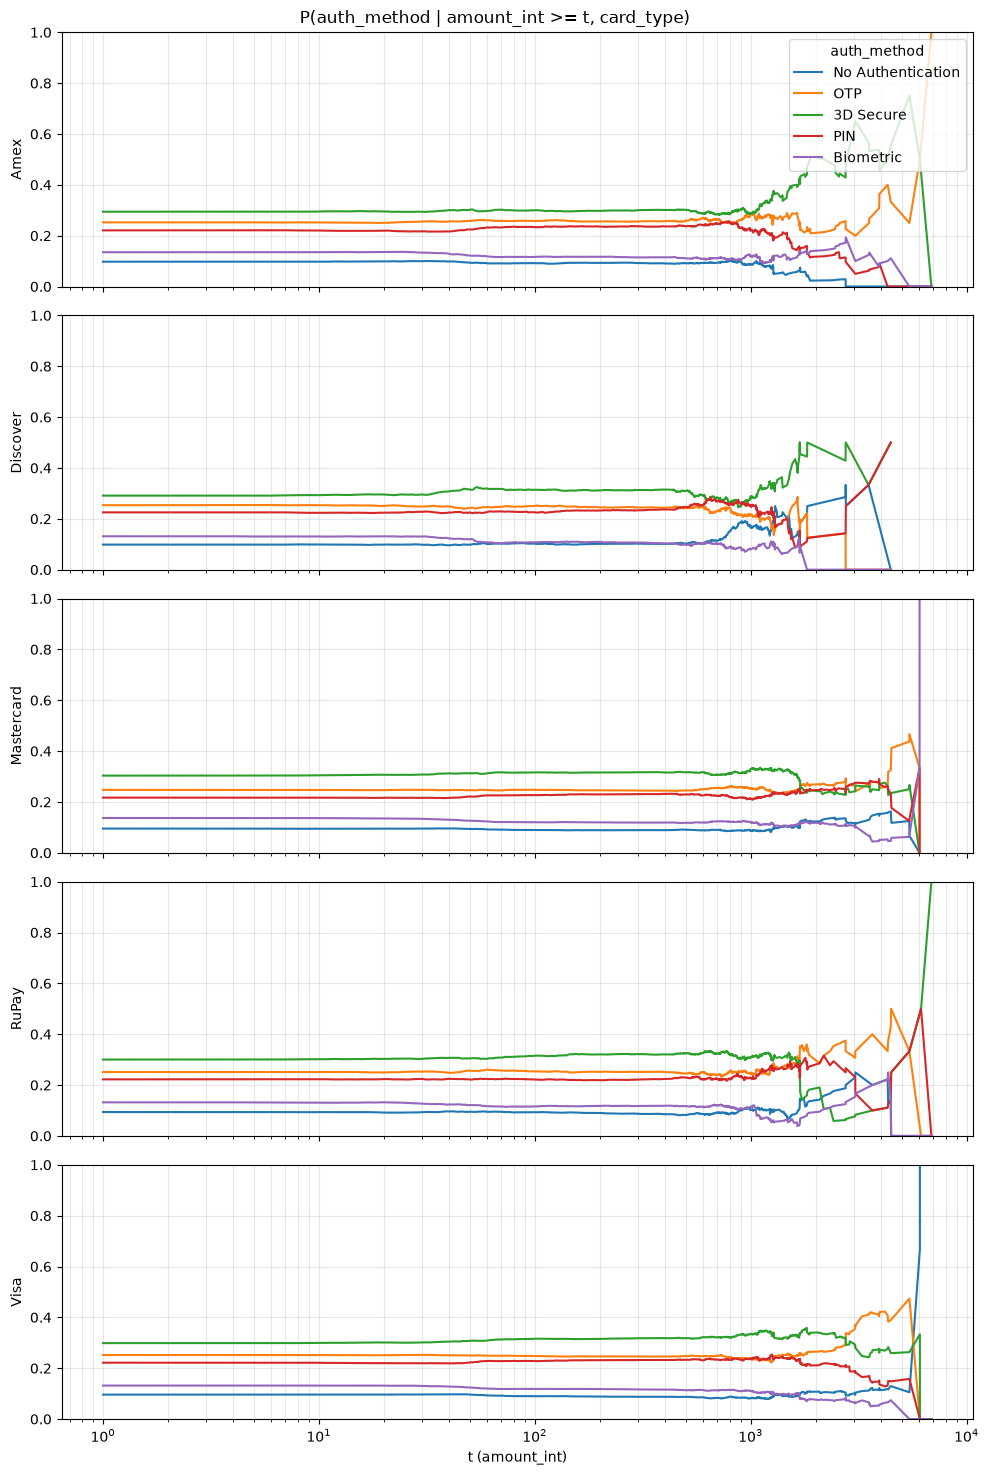

In [25]:
# same right-tail mix, split by card_type.

by_card_ge_parts = [None] * train_df[card_type_str].nunique()
for i, (card, part) in enumerate(train_df.groupby(card_type_str, sort=True)):
    mix_c = auth_mix_from_amount(part).reset_index()
    long_c = mix_c.melt(
        id_vars=["amount_int", "n_ge"],
        value_vars=auth_values,
        var_name=auth_method_str,
        value_name="p",
    )
    long_c[card_type_str] = card
    by_card_ge_parts[i] = long_c
mix_ge_by_card = pd.concat(by_card_ge_parts, ignore_index=True)
by_card_ge_path = tables_dir / "auth_mix_ge_amount_by_card_type.csv"
mix_ge_by_card.to_csv(by_card_ge_path, index=False)
print(f"saved {by_card_ge_path}")

cards = sorted(train_df[card_type_str].unique())
fig, axes = plt.subplots(len(cards), 1, figsize=(10, 3 * len(cards)), sharex=True)
for ax, card in zip(axes, cards):
    part = mix_ge_by_card.loc[mix_ge_by_card[card_type_str].eq(card)]
    for auth in auth_values:
        curve = part.loc[part[auth_method_str].eq(auth)]
        ax.plot(curve["amount_int"], curve["p"], label=auth)
    ax.set_xscale("log")
    ax.set_ylim(0, 1)
    ax.set_ylabel(card)
    ax.grid(True, which="both", alpha=0.3)
axes[0].legend(title=auth_method_str, loc="upper right")
axes[-1].set_xlabel("t (amount_int)")
fig.suptitle("P(auth_method | amount_int >= t, card_type)")
fig.tight_layout()
by_card_ge_plot_path = plots_dir / "auth_mix_ge_amount_by_card_type.png"
fig.savefig(by_card_ge_plot_path, dpi=140)
print(f"saved {by_card_ge_plot_path}")
plt.show()

# Amount threshold from left vs right auth mix

saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\tables\auth_mix_split_left_right.csv n_splits=1136
argmax L1(P(amount < t), P(amount >= t))
t                            1243.000000
n_left                     697480.000000
n_right                      2480.000000
l1                              0.111790
left_No Authentication          0.095845
right_No Authentication         0.084677
left_OTP                        0.250323
right_OTP                       0.235081
left_3D Secure                  0.299938
right_3D Secure                 0.336694
left_PIN                        0.219973
right_PIN                       0.239113
left_Biometric                  0.133921
right_Biometric                 0.104435
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\plots\auth_mix_split_left_right.png


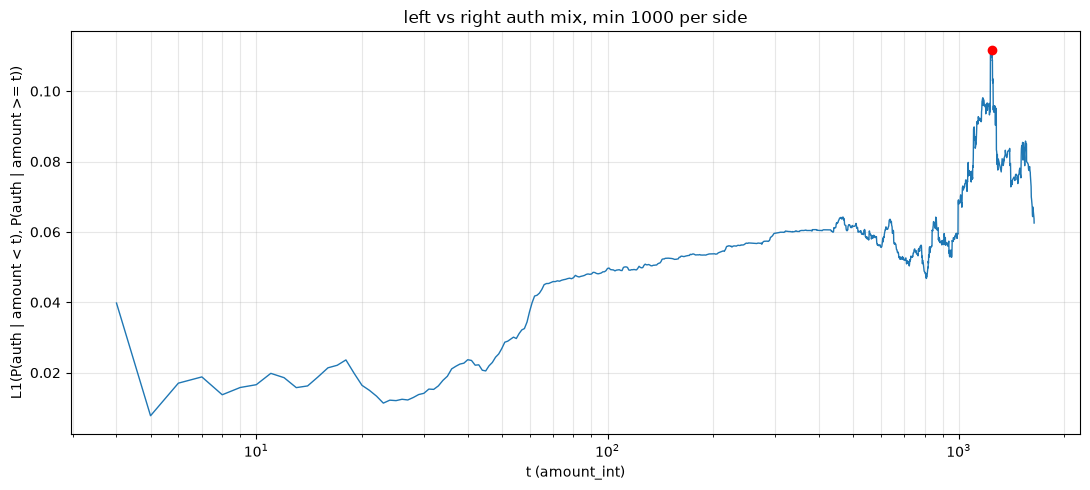

In [26]:
# P_left(t) = auth mix among amount_int < t
# P_right(t) = auth mix among amount_int >= t
# keep splits with at least 1000 rows on each side.
# score(t) = L1(P_left(t), P_right(t))

MIN_SIDE_N = 1000
ordered_amount = train_df["amount_int"].to_numpy()
order = np.argsort(ordered_amount, kind="mergesort")
amount_sorted = ordered_amount[order]
auth_sorted = train_df[auth_method_str].to_numpy()[order]
dummies = np.zeros((len(auth_sorted), len(auth_values)), dtype=np.int64)
for j, auth in enumerate(auth_values):
    dummies[:, j] = auth_sorted == auth
cs = np.cumsum(dummies, axis=0)
total_counts = cs[-1]
n_total = len(amount_sorted)
unique_t = np.unique(amount_sorted)
starts = np.searchsorted(amount_sorted, unique_t, side="left")
n_left = starts
n_right = n_total - starts
ok = (n_left >= MIN_SIDE_N) & (n_right >= MIN_SIDE_N)
starts_ok = starts[ok]
n_left_ok = n_left[ok]
n_right_ok = n_right[ok]
t_ok = unique_t[ok]
left_counts = cs[starts_ok - 1]
right_counts = total_counts - left_counts
p_left = left_counts / n_left_ok[:, None]
p_right = right_counts / n_right_ok[:, None]
l1 = np.abs(p_left - p_right).sum(axis=1)
split = pd.DataFrame(
    {
        "t": t_ok,
        "n_left": n_left_ok,
        "n_right": n_right_ok,
        "l1": l1,
    }
)
for j, auth in enumerate(auth_values):
    split[f"left_{auth}"] = p_left[:, j]
    split[f"right_{auth}"] = p_right[:, j]
split_path = tables_dir / "auth_mix_split_left_right.csv"
split.to_csv(split_path, index=False)
print(f"saved {split_path} n_splits={len(split)}")

best = split.loc[split["l1"].idxmax()]
amount_auth_threshold = int(best["t"])
print("argmax L1(P(amount < t), P(amount >= t))")
print(best.to_string())

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(split["t"], split["l1"], lw=1.0)
ax.scatter([best["t"]], [best["l1"]], c="red", zorder=3)
ax.set_xscale("log")
ax.set_xlabel("t (amount_int)")
ax.set_ylabel("L1(P(auth | amount < t), P(auth | amount >= t))")
ax.set_title(f"left vs right auth mix, min {MIN_SIDE_N} per side")
ax.grid(True, which="both", alpha=0.3)
fig.tight_layout()
split_plot_path = (
    get_script_plot_dir(
        NOTEBOOK_STEM, section="amount_threshold_from_left_vs_right_auth_mix"
    )
    / "auth_mix_split_left_right.png"
)
fig.savefig(split_plot_path, dpi=140)
print(f"saved {split_plot_path}")
plt.show()


In [27]:
# money x auth at t*: fraud rate for amount < t vs amount >= t, by auth_method.

print(f"threshold t={amount_auth_threshold}")
left_cols = [f"left_{auth}" for auth in auth_values]
right_cols = [f"right_{auth}" for auth in auth_values]
best_row = split.loc[split["t"].eq(amount_auth_threshold)].iloc[0]
print("P(auth | amount < t)")
print(best_row[left_cols].rename(lambda c: c.removeprefix("left_")).round(4))
print("P(auth | amount >= t)")
print(best_row[right_cols].rename(lambda c: c.removeprefix("right_")).round(4))

train_df["amount_ge_t"] = train_df["amount_int"].ge(amount_auth_threshold)
print(
    train_df.groupby("amount_ge_t")[TARGET].agg(
        n="size", n_fraud="sum", fraud_rate="mean"
    )
)

auth_by_side = (
    train_df.groupby(["amount_ge_t", auth_method_str], observed=True)[TARGET]
    .agg(n="size", n_fraud="sum", fraud_rate="mean")
    .reset_index()
)
auth_by_side["lift_vs_base"] = auth_by_side["fraud_rate"] / train_df[TARGET].mean()
auth_side_path = tables_dir / "fraud_rate_auth_by_amount_threshold.csv"
auth_by_side.to_csv(auth_side_path, index=False)
print(
    auth_by_side.sort_values(
        ["amount_ge_t", "fraud_rate"], ascending=[True, False]
    ).round(4)
)
print(f"saved {auth_side_path}")


threshold t=1243
P(auth | amount < t)
No Authentication    0.0958
OTP                  0.2503
3D Secure            0.2999
PIN                  0.2200
Biometric            0.1339
Name: 984, dtype: float64
P(auth | amount >= t)
No Authentication    0.0847
OTP                  0.2351
3D Secure            0.3367
PIN                  0.2391
Biometric            0.1044
Name: 984, dtype: float64
                  n  n_fraud  fraud_rate
amount_ge_t                             
False        697480  11630.0    0.016674
True           2480     59.0    0.023790
   amount_ge_t        auth_method       n  n_fraud  fraud_rate  lift_vs_base
2        False  No Authentication   66850   4305.0      0.0644        3.8563
0        False          3D Secure  209201   3080.0      0.0147        0.8816
3        False                OTP  174595   2452.0      0.0140        0.8410
4        False                PIN  153427   1328.0      0.0087        0.5183
1        False          Biometric   93407    465.0      0.0

# Amount threshold from left vs right auth mix, by card type

Amex: n=45797 n_splits=497 t*=616 L1=0.0849 n_left=43972 n_right=1825
Discover: n=17235 n_splits=236 t*=478 L1=0.0974 n_left=16209 n_right=1026
Mastercard: n=254857 n_splits=875 t*=1105 L1=0.0772 n_left=253564 n_right=1293
RuPay: n=37070 n_splits=448 t*=647 L1=0.0775 n_left=35860 n_right=1210
Visa: n=345001 n_splits=951 t*=1243 L1=0.1414 n_left=343779 n_right=1222
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\tables\auth_mix_split_left_right_by_card_type.csv
saved C:\Users\bouab\ayhem-personal\DEV\ML\DL_projects\kaggle_comps\CreditCardFraud\storage\artifacts\eda_1_notebook\tables\auth_mix_split_best_t_by_card_type.csv
               t  n_left  n_right      l1
card_type                                
Amex         616   43972     1825  0.0849
Discover     478   16209     1026  0.0974
Mastercard  1105  253564     1293  0.0772
RuPay        647   35860     1210  0.0775
Visa        1243  343779     1222  0.1414
saved C:\

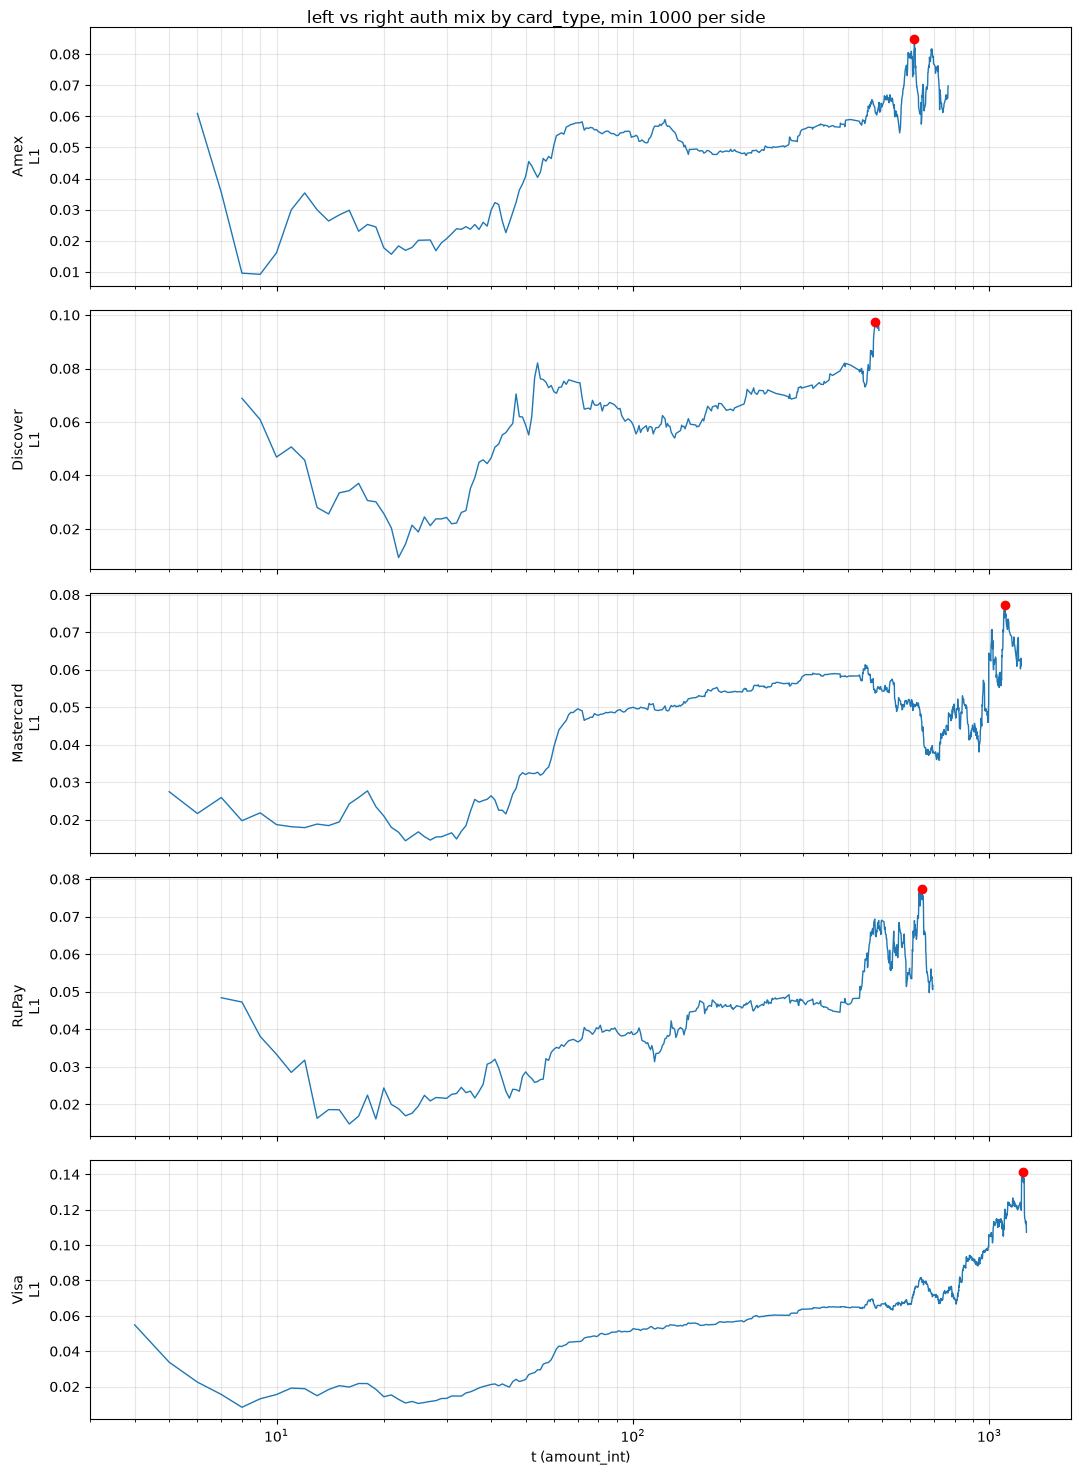

In [28]:
# same split as above, one curve per card_type.
# min 1000 rows on each side is inside that card, not globally.

def auth_mix_split_left_right(frame, *, min_side_n):
    """L1 between P(auth | amount < t) and P(auth | amount >= t).

    Only keeps t with at least min_side_n rows on each side.
    """
    ordered_amount = frame["amount_int"].to_numpy()
    order = np.argsort(ordered_amount, kind="mergesort")
    amount_sorted = ordered_amount[order]
    auth_sorted = frame[auth_method_str].to_numpy()[order]
    dummies = np.zeros((len(auth_sorted), len(auth_values)), dtype=np.int64)
    for j, auth in enumerate(auth_values):
        dummies[:, j] = auth_sorted == auth
    cs = np.cumsum(dummies, axis=0)
    total_counts = cs[-1]
    n_total = len(amount_sorted)
    unique_t = np.unique(amount_sorted)
    starts = np.searchsorted(amount_sorted, unique_t, side="left")
    n_left = starts
    n_right = n_total - starts
    ok = (n_left >= min_side_n) & (n_right >= min_side_n)
    if not np.any(ok):
        return pd.DataFrame(
            columns=["t", "n_left", "n_right", "l1"]
            + [f"left_{auth}" for auth in auth_values]
            + [f"right_{auth}" for auth in auth_values]
        )
    starts_ok = starts[ok]
    n_left_ok = n_left[ok]
    n_right_ok = n_right[ok]
    t_ok = unique_t[ok]
    left_counts = cs[starts_ok - 1]
    right_counts = total_counts - left_counts
    p_left = left_counts / n_left_ok[:, None]
    p_right = right_counts / n_right_ok[:, None]
    l1 = np.abs(p_left - p_right).sum(axis=1)
    out = pd.DataFrame(
        {
            "t": t_ok,
            "n_left": n_left_ok,
            "n_right": n_right_ok,
            "l1": l1,
        }
    )
    for j, auth in enumerate(auth_values):
        out[f"left_{auth}"] = p_left[:, j]
        out[f"right_{auth}"] = p_right[:, j]
    return out

cards = sorted(train_df[card_type_str].unique())
split_by_card_parts = [None] * len(cards)
best_by_card_rows = [None] * len(cards)
for i, card in enumerate(cards):
    part = train_df.loc[train_df[card_type_str].eq(card)]
    split_c = auth_mix_split_left_right(part, min_side_n=MIN_SIDE_N)
    split_c[card_type_str] = card
    split_by_card_parts[i] = split_c
    if split_c.empty:
        print(f"{card}: no t with {MIN_SIDE_N} on both sides, n={len(part)}")
        continue
    best_c = split_c.loc[split_c["l1"].idxmax()]
    best_by_card_rows[i] = best_c
    print(
        f"{card}: n={len(part)} n_splits={len(split_c)} "
        f"t*={int(best_c['t'])} L1={best_c['l1']:.4f} "
        f"n_left={int(best_c['n_left'])} n_right={int(best_c['n_right'])}"
    )

split_by_card = pd.concat(split_by_card_parts, ignore_index=True)
split_by_card_path = tables_dir / "auth_mix_split_left_right_by_card_type.csv"
split_by_card.to_csv(split_by_card_path, index=False)
print(f"saved {split_by_card_path}")

best_by_card = pd.DataFrame(
    [row for row in best_by_card_rows if row is not None]
)
best_by_card_path = tables_dir / "auth_mix_split_best_t_by_card_type.csv"
best_by_card.to_csv(best_by_card_path, index=False)
print(f"saved {best_by_card_path}")
print(best_by_card.set_index(card_type_str)[["t", "n_left", "n_right", "l1"]].round(4))

fig, axes = plt.subplots(len(cards), 1, figsize=(11, 3 * len(cards)), sharex=True)
for ax, card in zip(axes, cards):
    part = split_by_card.loc[split_by_card[card_type_str].eq(card)]
    ax.plot(part["t"], part["l1"], lw=1.0)
    if not part.empty:
        peak = part.loc[part["l1"].idxmax()]
        ax.scatter([peak["t"]], [peak["l1"]], c="red", zorder=3)
        ax.set_ylabel(f"{card}\nL1")
    ax.set_xscale("log")
    ax.grid(True, which="both", alpha=0.3)
axes[-1].set_xlabel("t (amount_int)")
fig.suptitle(
    f"left vs right auth mix by card_type, min {MIN_SIDE_N} per side"
)
fig.tight_layout()
split_by_card_plot_path = (
    get_script_plot_dir(
        NOTEBOOK_STEM,
        section="amount_threshold_from_left_vs_right_auth_mix_by_card_type",
    )
    / "auth_mix_split_left_right_by_card_type.png"
)
fig.savefig(split_by_card_plot_path, dpi=140)
print(f"saved {split_by_card_plot_path}")
plt.show()


In [29]:
# money x auth at each card's t*: fraud below vs at-or-above, inside that card.

left_cols = [f"left_{auth}" for auth in auth_values]
right_cols = [f"right_{auth}" for auth in auth_values]
fraud_by_card_parts = [None] * len(best_by_card)
for i, mix_row in best_by_card.reset_index(drop=True).iterrows():
    card = mix_row[card_type_str]
    t_star = int(mix_row["t"])
    print(f"\n{card} t*={t_star}")
    print("P(auth | amount < t)")
    print(mix_row[left_cols].rename(lambda c: c.removeprefix("left_")).round(4))
    print("P(auth | amount >= t)")
    print(mix_row[right_cols].rename(lambda c: c.removeprefix("right_")).round(4))
    card_df = train_df.loc[train_df[card_type_str].eq(card)].copy()
    card_df["amount_ge_t"] = card_df["amount_int"].ge(t_star)
    print(
        card_df.groupby("amount_ge_t")[TARGET].agg(
            n="size", n_fraud="sum", fraud_rate="mean"
        )
    )
    auth_side = (
        card_df.groupby(["amount_ge_t", auth_method_str], observed=True)[TARGET]
        .agg(n="size", n_fraud="sum", fraud_rate="mean")
        .reset_index()
    )
    auth_side[card_type_str] = card
    auth_side["t"] = t_star
    auth_side["lift_vs_card"] = auth_side["fraud_rate"] / card_df[TARGET].mean()
    fraud_by_card_parts[i] = auth_side
    print(
        auth_side.sort_values(
            ["amount_ge_t", "fraud_rate"], ascending=[True, False]
        ).round(4)
    )

fraud_by_card = pd.concat(fraud_by_card_parts, ignore_index=True)
fraud_by_card_path = tables_dir / "fraud_rate_auth_by_amount_threshold_by_card_type.csv"
fraud_by_card.to_csv(fraud_by_card_path, index=False)
print(f"saved {fraud_by_card_path}")



Amex t*=616
P(auth | amount < t)
No Authentication    0.0979
OTP                  0.2517
3D Secure            0.2946
PIN                  0.2198
Biometric             0.136
Name: 0, dtype: object
P(auth | amount >= t)
No Authentication    0.0921
OTP                  0.2679
3D Secure            0.2877
PIN                   0.246
Biometric            0.1063
Name: 0, dtype: object
                 n  n_fraud  fraud_rate
amount_ge_t                            
False        43972    838.0    0.019058
True          1825     33.0    0.018082
   amount_ge_t        auth_method      n  n_fraud  fraud_rate card_type    t  \
2        False  No Authentication   4303    338.0      0.0785      Amex  616   
0        False          3D Secure  12954    212.0      0.0164      Amex  616   
3        False                OTP  11066    170.0      0.0154      Amex  616   
4        False                PIN   9667     94.0      0.0097      Amex  616   
1        False          Biometric   5982     24.0      0.0